# Segundo trabajo de la asignatura: Redes Neuronales y Algoritmos Bioinspirados. 


**Universidad Nacional de Colombia**

Departamento de Ciencias de la Computación y de la Decisión

Integrantes:  

**-Juan Manuel Diaz Larrea**

**-Kevin Hair González Duarte**

**-Manuel Gutierrez Tangarife**

**-Mariana Ruiz Zamora**

**-Maria Fernanda Valencia Jimenez**



Semestre 2026-02


# Solución parte 1: Probabilidad de incumplimiento (clasificación binaria) 

**Objetivo: Modelar la probabilidad de que un cliente sea "malo", es decir, que incumpla con el pago de su crédito**

In [60]:
#Cargar librerías 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.api as sm
import joblib
from sklearn.preprocessing import StandardScaler
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [34]:
#Lectura de datos   

#Fecha de descarga: 24/10/2026

datos= pd.read_csv("loan.csv")



C:\Users\Maria Fernanda\AppData\Local\Temp\ipykernel_5412\212864074.py:5: DtypeWarning: Columns (0: desc, 1: verification_status_joint) have mixed types. Specify dtype option on import or set low_memory=False.
  datos= pd.read_csv("loan.csv")


In [35]:
#Verificar que se leyó bien la bd

datos.head()
datos.tail()
datos.sample(6)

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
592120,60924261,64966121,5600.0,5600.0,5600.0,36 months,10.99,183.32,B,B4,...,NaN,NaN,NaN,NaN,NaN,NaN,9600.0,NaN,NaN,NaN
774902,46752674,49900404,16000.0,16000.0,16000.0,60 months,13.33,366.76,C,C3,...,NaN,NaN,NaN,NaN,NaN,NaN,36300.0,NaN,NaN,NaN
709540,52868336,56368053,25600.0,25600.0,25600.0,60 months,7.89,517.73,A,A5,...,NaN,NaN,NaN,NaN,NaN,NaN,82700.0,NaN,NaN,NaN
712635,51246495,54666243,3600.0,3600.0,3600.0,36 months,18.25,130.61,E,E1,...,NaN,NaN,NaN,NaN,NaN,NaN,23700.0,NaN,NaN,NaN
192264,1600751,1871628,9000.0,9000.0,8750.0,36 months,13.11,303.73,B,B4,...,NaN,NaN,NaN,NaN,NaN,NaN,14800.0,NaN,NaN,NaN
653033,57274740,60977475,15425.0,15425.0,15425.0,60 months,14.65,364.14,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,8100.0,NaN,NaN,NaN


In [36]:
#Tamaño de la bd

datos.shape

#Hay 887,379 filas y 74 columnas 

(887379, 74)

In [37]:
#Cuáles son las columnas de la bd y qué representan

datos.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose',
       'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint',
    

Según el sitio web: https://www.kaggle.com/datasets/ranadeep/credit-risk-dataset/data el diccionario de datos es:

### Identificación y tipo de solicitud

<table style="width:100%">
<colgroup><col style="width:26%"><col style="width:74%"></colgroup>
<thead><tr><th style="text-align:left">Variable</th><th style="text-align:left">Descripción</th></tr></thead>
<tbody>
<tr><td style="text-align:left"><code>id</code></td><td style="text-align:left">Identificador único del listado del préstamo, asignado por LC.</td></tr>
<tr><td style="text-align:left"><code>member_id</code></td><td style="text-align:left">Identificador único del miembro prestatario, asignado por LC.</td></tr>
<tr><td style="text-align:left"><code>url</code></td><td style="text-align:left">URL de la página de LC con los datos del listado.</td></tr>
<tr><td style="text-align:left"><code>policy_code</code></td><td style="text-align:left">Productos disponibles al público: <code>policy_code</code>&nbsp;=&nbsp;1.<br> Productos nuevos no disponibles al público: <code>policy_code</code>&nbsp;=&nbsp;2.</td></tr>
<tr><td style="text-align:left"><code>initial_list_status</code></td><td style="text-align:left">Estado inicial de publicación del préstamo. Los valores posibles son W y F.</td></tr>
<tr><td style="text-align:left"><code>application_type</code></td><td style="text-align:left">Indica si el préstamo corresponde a una solicitud individual o a una solicitud conjunta con dos coprestatarios.</td></tr>
</tbody>
</table>

### Condiciones del préstamo

<table style="width:100%">
<colgroup><col style="width:26%"><col style="width:74%"></colgroup>
<thead><tr><th style="text-align:left">Variable</th><th style="text-align:left">Descripción</th></tr></thead>
<tbody>
<tr><td style="text-align:left"><code>loan_amnt</code></td><td style="text-align:left">Monto del préstamo solicitado por el prestatario, tal como figura en el listado. Si en algún momento el departamento de crédito reduce el monto del préstamo, dicha reducción se verá reflejada en este valor.</td></tr>
<tr><td style="text-align:left"><code>funded_amnt</code></td><td style="text-align:left">Monto total comprometido (financiado) para ese préstamo en ese momento.</td></tr>
<tr><td style="text-align:left"><code>funded_amnt_inv</code></td><td style="text-align:left">Monto total comprometido por los inversionistas para ese préstamo en ese momento.</td></tr>
<tr><td style="text-align:left"><code>term</code></td><td style="text-align:left">Número de pagos del préstamo. Los valores están expresados en meses y pueden ser 36 o 60.</td></tr>
<tr><td style="text-align:left"><code>int_rate</code></td><td style="text-align:left">Tasa de interés del préstamo.</td></tr>
<tr><td style="text-align:left"><code>installment</code></td><td style="text-align:left">Cuota mensual que debe pagar el prestatario si el préstamo se origina.</td></tr>
<tr><td style="text-align:left"><code>grade</code></td><td style="text-align:left">Calificación (<i>grade</i>) del préstamo asignada por LC.</td></tr>
<tr><td style="text-align:left"><code>sub_grade</code></td><td style="text-align:left">Subcalificación (<i>subgrade</i>) del préstamo asignada por LC.</td></tr>
<tr><td style="text-align:left"><code>issue_d</code></td><td style="text-align:left">Mes en que se desembolsó (financió) el préstamo.</td></tr>
<tr><td style="text-align:left"><code>purpose</code></td><td style="text-align:left">Categoría indicada por el prestatario como finalidad del préstamo solicitado.</td></tr>
<tr><td style="text-align:left"><code>title</code></td><td style="text-align:left">Título del préstamo indicado por el prestatario.</td></tr>
<tr><td style="text-align:left"><code>desc</code></td><td style="text-align:left">Descripción del préstamo proporcionada por el prestatario.</td></tr>
<tr><td style="text-align:left"><code>pymnt_plan</code></td><td style="text-align:left">Indica si se estableció un plan de pagos para el préstamo.</td></tr>
<tr><td style="text-align:left"><code>loan_status</code></td><td style="text-align:left">Estado actual del préstamo.</td></tr>
</tbody>
</table>

###  Perfil del prestatario

<table style="width:100%">
<colgroup><col style="width:26%"><col style="width:74%"></colgroup>
<thead><tr><th style="text-align:left">Variable</th><th style="text-align:left">Descripción</th></tr></thead>
<tbody>
<tr><td style="text-align:left"><code>addr_state</code></td><td style="text-align:left">Estado (de EE.&nbsp;UU.) indicado por el prestatario en la solicitud del préstamo.</td></tr>
<tr><td style="text-align:left"><code>zip_code</code></td><td style="text-align:left">Los tres primeros dígitos del código postal indicado por el prestatario en la solicitud del préstamo.</td></tr>
<tr><td style="text-align:left"><code>emp_title</code></td><td style="text-align:left">Cargo (título del puesto de trabajo) indicado por el prestatario al solicitar el préstamo.<sup>*</sup></td></tr>
<tr><td style="text-align:left"><code>emp_length</code></td><td style="text-align:left">Antigüedad laboral en años. Los valores posibles van de 0 a 10, donde 0 significa menos de un año y 10 significa diez años o más.</td></tr>
<tr><td style="text-align:left"><code>home_ownership</code></td><td style="text-align:left">Situación de vivienda del prestatario informada durante el registro. Los valores son: RENT (arriendo), OWN (vivienda propia), MORTGAGE (vivienda con hipoteca) y OTHER (otra).</td></tr>
<tr><td style="text-align:left"><code>annual_inc</code></td><td style="text-align:left">Ingreso anual autodeclarado por el prestatario durante el registro.</td></tr>
<tr><td style="text-align:left"><code>annual_inc_joint</code></td><td style="text-align:left">Ingreso anual combinado, autodeclarado por los coprestatarios durante el registro.</td></tr>
<tr><td style="text-align:left"><code>dti</code></td><td style="text-align:left">Razón (relación deuda-ingreso) calculada como los pagos mensuales totales del prestatario por el total de sus obligaciones de deuda, excluyendo la hipoteca y el préstamo solicitado a LC, dividida entre el ingreso mensual autodeclarado del prestatario.</td></tr>
<tr><td style="text-align:left"><code>dti_joint</code></td><td style="text-align:left">Razón (relación deuda-ingreso conjunta) calculada como los pagos mensuales totales de los coprestatarios por el total de sus obligaciones de deuda, excluyendo las hipotecas y el préstamo solicitado a LC, dividida entre el ingreso mensual combinado autodeclarado de los coprestatarios.</td></tr>
<tr><td style="text-align:left"><code>is_inc_v</code></td><td style="text-align:left">Indica si LC verificó el ingreso, si no fue verificado o si se verificó la fuente del ingreso.</td></tr>
<tr><td style="text-align:left"><code>verified_status_joint</code></td><td style="text-align:left">Indica si LC verificó el ingreso conjunto de los coprestatarios, si no fue verificado o si se verificó la fuente del ingreso.</td></tr>
</tbody>
</table>

### Historial crediticio general

<table style="width:100%">
<colgroup><col style="width:26%"><col style="width:74%"></colgroup>
<thead><tr><th style="text-align:left">Variable</th><th style="text-align:left">Descripción</th></tr></thead>
<tbody>
<tr><td style="text-align:left"><code>fico_range_low</code></td><td style="text-align:left">Límite inferior del rango al que pertenece el puntaje FICO del prestatario en el momento de originación del préstamo.</td></tr>
<tr><td style="text-align:left"><code>fico_range_high</code></td><td style="text-align:left">Límite superior del rango al que pertenece el puntaje FICO del prestatario en el momento de originación del préstamo.</td></tr>
<tr><td style="text-align:left"><code>last_fico_range_low</code></td><td style="text-align:left">Límite inferior del rango al que pertenece el último puntaje FICO consultado del prestatario.</td></tr>
<tr><td style="text-align:left"><code>last_fico_range_high</code></td><td style="text-align:left">Límite superior del rango al que pertenece el último puntaje FICO consultado del prestatario.</td></tr>
<tr><td style="text-align:left"><code>earliest_cr_line</code></td><td style="text-align:left">Mes en que se abrió la línea de crédito más antigua reportada del prestatario.</td></tr>
<tr><td style="text-align:left"><code>last_credit_pull_d</code></td><td style="text-align:left">Mes más reciente en que LC consultó el reporte de crédito para este préstamo.</td></tr>
<tr><td style="text-align:left"><code>inq_last_6mths</code></td><td style="text-align:left">Número de consultas crediticias en los últimos 6 meses (excluyendo las consultas por crédito de vehículo e hipotecario).</td></tr>
<tr><td style="text-align:left"><code>inq_last_12m</code></td><td style="text-align:left">Número de consultas crediticias en los últimos 12 meses.</td></tr>
<tr><td style="text-align:left"><code>inq_fi</code></td><td style="text-align:left">Número de consultas crediticias de finanzas personales.</td></tr>
<tr><td style="text-align:left"><code>open_acc</code></td><td style="text-align:left">Número de líneas de crédito abiertas en el historial crediticio del prestatario.</td></tr>
<tr><td style="text-align:left"><code>total_acc</code></td><td style="text-align:left">Número total de líneas de crédito que figuran actualmente en el historial crediticio del prestatario.</td></tr>
<tr><td style="text-align:left"><code>pub_rec</code></td><td style="text-align:left">Número de registros públicos desfavorables (<i>derogatory</i>).</td></tr>
<tr><td style="text-align:left"><code>revol_bal</code></td><td style="text-align:left">Saldo total del crédito rotativo.</td></tr>
<tr><td style="text-align:left"><code>revol_util</code></td><td style="text-align:left">Tasa de utilización de las líneas rotativas, es decir, la proporción del crédito que el prestatario está usando con respecto al total del crédito rotativo disponible.</td></tr>
<tr><td style="text-align:left"><code>total_rev_hi_lim</code></td><td style="text-align:left">Total del crédito máximo/límite de crédito de las cuentas rotativas.</td></tr>
<tr><td style="text-align:left"><code>tot_cur_bal</code></td><td style="text-align:left">Saldo actual total de todas las cuentas.</td></tr>
<tr><td style="text-align:left"><code>total_cu_tl</code></td><td style="text-align:left">Número de líneas de crédito de financiamiento (<i>finance trades</i>).</td></tr>
<tr><td style="text-align:left"><code>all_util</code></td><td style="text-align:left">Razón entre el saldo y el límite de crédito de todas las líneas de crédito.</td></tr>
<tr><td style="text-align:left"><code>max_bal_bc</code></td><td style="text-align:left">Saldo actual máximo adeudado en todas las cuentas rotativas.</td></tr>
</tbody>
</table>

### Cuentas a cuotas y rotativas

<table style="width:100%">
<colgroup><col style="width:26%"><col style="width:74%"></colgroup>
<thead><tr><th style="text-align:left">Variable</th><th style="text-align:left">Descripción</th></tr></thead>
<tbody>
<tr><td style="text-align:left"><code>open_acc_6m</code></td><td style="text-align:left">Número de líneas de crédito (<i>trades</i>) abiertas en los últimos 6 meses.</td></tr>
<tr><td style="text-align:left"><code>open_il_6m</code></td><td style="text-align:left">Número de líneas de crédito a cuotas (<i>installment</i>) actualmente activas.</td></tr>
<tr><td style="text-align:left"><code>open_il_12m</code></td><td style="text-align:left">Número de cuentas a cuotas abiertas en los últimos 12 meses.</td></tr>
<tr><td style="text-align:left"><code>open_il_24m</code></td><td style="text-align:left">Número de cuentas a cuotas abiertas en los últimos 24 meses.</td></tr>
<tr><td style="text-align:left"><code>mths_since_rcnt_il</code></td><td style="text-align:left">Meses transcurridos desde la apertura de la cuenta a cuotas más reciente.</td></tr>
<tr><td style="text-align:left"><code>total_bal_il</code></td><td style="text-align:left">Saldo actual total de todas las cuentas a cuotas.</td></tr>
<tr><td style="text-align:left"><code>il_util</code></td><td style="text-align:left">Razón entre el saldo actual total y el crédito máximo/límite de crédito de todas las cuentas a cuotas.</td></tr>
<tr><td style="text-align:left"><code>open_rv_12m</code></td><td style="text-align:left">Número de líneas de crédito rotativas abiertas en los últimos 12 meses.</td></tr>
<tr><td style="text-align:left"><code>open_rv_24m</code></td><td style="text-align:left">Número de líneas de crédito rotativas abiertas en los últimos 24 meses.</td></tr>
</tbody>
</table>

###  Mora y cobranza

<table style="width:100%">
<colgroup><col style="width:26%"><col style="width:74%"></colgroup>
<thead><tr><th style="text-align:left">Variable</th><th style="text-align:left">Descripción</th></tr></thead>
<tbody>
<tr><td style="text-align:left"><code>delinq_2yrs</code></td><td style="text-align:left">Número de episodios de mora de 30 o más días de vencimiento registrados en el historial crediticio del prestatario durante los últimos 2 años.</td></tr>
<tr><td style="text-align:left"><code>mths_since_last_delinq</code></td><td style="text-align:left">Número de meses transcurridos desde la última mora del prestatario.</td></tr>
<tr><td style="text-align:left"><code>mths_since_last_major_derog</code></td><td style="text-align:left">Meses transcurridos desde la calificación más reciente de 90 días de mora o peor.</td></tr>
<tr><td style="text-align:left"><code>mths_since_last_record</code></td><td style="text-align:left">Número de meses transcurridos desde el último registro público.</td></tr>
<tr><td style="text-align:left"><code>acc_now_delinq</code></td><td style="text-align:left">Número de cuentas en las que el prestatario se encuentra actualmente en mora.</td></tr>
<tr><td style="text-align:left"><code>collections_12_mths_ex_med</code></td><td style="text-align:left">Número de cobranzas en los últimos 12 meses, excluyendo las cobranzas de origen médico.</td></tr>
<tr><td style="text-align:left"><code>tot_coll_amt</code></td><td style="text-align:left">Monto total histórico adeudado en cobranza.</td></tr>
</tbody>
</table>

### Pagos y recuperaciones

<table style="width:100%">
<colgroup><col style="width:26%"><col style="width:74%"></colgroup>
<thead><tr><th style="text-align:left">Variable</th><th style="text-align:left">Descripción</th></tr></thead>
<tbody>
<tr><td style="text-align:left"><code>out_prncp</code></td><td style="text-align:left">Capital pendiente por pagar sobre el monto total financiado.</td></tr>
<tr><td style="text-align:left"><code>out_prncp_inv</code></td><td style="text-align:left">Capital pendiente por pagar sobre la porción del monto total financiado por los inversionistas.</td></tr>
<tr><td style="text-align:left"><code>total_pymnt</code></td><td style="text-align:left">Pagos recibidos a la fecha sobre el monto total financiado.</td></tr>
<tr><td style="text-align:left"><code>total_pymnt_inv</code></td><td style="text-align:left">Pagos recibidos a la fecha sobre la porción del monto total financiado por los inversionistas.</td></tr>
<tr><td style="text-align:left"><code>total_rec_prncp</code></td><td style="text-align:left">Capital recibido a la fecha.</td></tr>
<tr><td style="text-align:left"><code>total_rec_int</code></td><td style="text-align:left">Intereses recibidos a la fecha.</td></tr>
<tr><td style="text-align:left"><code>total_rec_late_fee</code></td><td style="text-align:left">Cargos por pago tardío recibidos a la fecha.</td></tr>
<tr><td style="text-align:left"><code>recoveries</code></td><td style="text-align:left">Recuperación bruta posterior al castigo de cartera (<i>charge off</i>).</td></tr>
<tr><td style="text-align:left"><code>collection_recovery_fee</code></td><td style="text-align:left">Comisión de cobranza posterior al castigo de cartera (<i>charge off</i>).</td></tr>
<tr><td style="text-align:left"><code>last_pymnt_d</code></td><td style="text-align:left">Mes en que se recibió el último pago.</td></tr>
<tr><td style="text-align:left"><code>last_pymnt_amnt</code></td><td style="text-align:left">Monto total del último pago recibido.</td></tr>
<tr><td style="text-align:left"><code>next_pymnt_d</code></td><td style="text-align:left">Fecha programada del próximo pago.</td></tr>
</tbody>
</table>

<sup>*</sup> El cargo (<i>Employer Title</i>) reemplaza al nombre del empleador en todos los préstamos listados después del 23 de septiembre de 2013.

In [38]:
#Verificar si hay valores duplicados en la bd

print("Número de filas antes de eliminar registros duplicados:", datos.shape[0])
datos = datos.drop_duplicates()
print("Número de filas después de eliminar registros duplicados:", datos.shape[0])

#No hay registros duplicados en la bd 

Número de filas antes de eliminar registros duplicados: 887379
Número de filas después de eliminar registros duplicados: 887379


In [39]:
#información de la bd

datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 887379 entries, 0 to 887378
Data columns (total 74 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           887379 non-null  int64  
 1   member_id                    887379 non-null  int64  
 2   loan_amnt                    887379 non-null  float64
 3   funded_amnt                  887379 non-null  float64
 4   funded_amnt_inv              887379 non-null  float64
 5   term                         887379 non-null  str    
 6   int_rate                     887379 non-null  float64
 7   installment                  887379 non-null  float64
 8   grade                        887379 non-null  str    
 9   sub_grade                    887379 non-null  str    
 10  emp_title                    835917 non-null  str    
 11  emp_length                   842554 non-null  str    
 12  home_ownership               887379 non-null  str    
 13  annual_inc

In [40]:
#Resumen de las variables numéricas de la bd

datos.describe()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
count,8.873790e+05,8.873790e+05,887379.000000,887379.000000,887379.000000,887379.000000,887379.000000,8.873750e+05,887379.000000,887350.000000,...,21372.000000,18617.000000,21372.000000,21372.000000,21372.000000,21372.000000,8.171030e+05,21372.000000,21372.000000,21372.000000
mean,3.246513e+07,3.500182e+07,14755.264605,14741.877625,14702.464383,13.246740,436.717127,7.502759e+04,18.157039,0.314442,...,36552.811389,71.535317,1.389060,2.975482,5887.979740,60.831939,3.206862e+04,0.943945,1.537058,1.977307
std,2.282734e+07,2.411335e+07,8435.455601,8429.897657,8442.106732,4.381867,244.186593,6.469830e+04,17.190626,0.862244,...,43103.833619,23.022862,1.520129,2.631886,5284.701239,20.013254,3.749826e+04,1.446872,2.723339,2.874067
min,5.473400e+04,7.047300e+04,500.000000,500.000000,0.000000,5.320000,15.670000,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,-4.000000
25%,9.206643e+06,1.087713e+07,8000.000000,8000.000000,8000.000000,9.990000,260.705000,4.500000e+04,11.910000,0.000000,...,10251.500000,58.600000,0.000000,1.000000,2411.000000,47.700000,1.390000e+04,0.000000,0.000000,0.000000
50%,3.443327e+07,3.709528e+07,13000.000000,13000.000000,13000.000000,12.990000,382.550000,6.500000e+04,17.650000,0.000000,...,24684.500000,74.900000,1.000000,2.000000,4483.000000,61.900000,2.370000e+04,0.000000,0.000000,2.000000
75%,5.490814e+07,5.847135e+07,20000.000000,20000.000000,20000.000000,16.200000,572.600000,9.000000e+04,23.950000,0.000000,...,47858.000000,87.600000,2.000000,4.000000,7771.500000,75.200000,3.980000e+04,1.000000,2.000000,3.000000
max,6.861706e+07,7.354484e+07,35000.000000,35000.000000,35000.000000,28.990000,1445.460000,9.500000e+06,9999.000000,39.000000,...,878459.000000,223.300000,22.000000,43.000000,127305.000000,151.400000,9.999999e+06,17.000000,35.000000,32.000000


In [41]:
#Resumen de las variables categóricas de la bd

datos.describe(include="object")

C:\Users\Maria Fernanda\AppData\Local\Temp\ipykernel_5412\3657833786.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  datos.describe(include="object")


,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,pymnt_plan,...,title,zip_code,addr_state,earliest_cr_line,initial_list_status,last_pymnt_d,next_pymnt_d,last_credit_pull_d,application_type,verification_status_joint
count,887379,887379,887379,835917,842554,887379,887379,887379,887379,887379,...,887226,887379,887379,887350,887379,869720,634408,887326,887379,511
unique,2,7,35,299271,11,6,3,103,10,2,...,63143,935,51,697,2,98,100,103,2,3
top,36 months,B,B3,Teacher,10+ years,MORTGAGE,Source Verified,Oct-2015,Current,n,...,Debt consolidation,945xx,CA,Aug-2001,f,Jan-2016,Feb-2016,Jan-2016,INDIVIDUAL,Not Verified
freq,621125,254535,56323,13469,291569,443557,329558,48631,601779,887369,...,414001,9770,129517,6659,456848,470150,553406,730574,886868,283


In [42]:
#Verificar valores nulos

datos.isna().sum()

id                       0
member_id                0
loan_amnt                0
funded_amnt              0
funded_amnt_inv          0
                     ...  
all_util            866007
total_rev_hi_lim     70276
inq_fi              866007
total_cu_tl         866007
inq_last_12m        866007
Length: 74, dtype: int64

In [43]:
#Porcentaje de valores nulos por columna

datos.isnull().sum() / len(datos) * 100

id                   0.000000
member_id            0.000000
loan_amnt            0.000000
funded_amnt          0.000000
funded_amnt_inv      0.000000
                      ...    
all_util            97.591559
total_rev_hi_lim     7.919502
inq_fi              97.591559
total_cu_tl         97.591559
inq_last_12m        97.591559
Length: 74, dtype: float64

In [44]:
#Eliminación de columnas con más del 90% de valores nulos

umbral = 90 
columnas_nulos = datos.isnull().sum() / len(datos) * 100

cols_eliminar = columnas_nulos[columnas_nulos > umbral].index.tolist()

print(f"Se eliminan {len(cols_eliminar)} columnas:")
print(columnas_nulos[cols_eliminar].round(2).sort_values(ascending=False))

datos = datos.drop(columns=cols_eliminar)




Se eliminan 17 columnas:
annual_inc_joint             99.94
dti_joint                    99.94
verification_status_joint    99.94
il_util                      97.90
mths_since_rcnt_il           97.65
open_il_6m                   97.59
open_il_12m                  97.59
open_il_24m                  97.59
open_acc_6m                  97.59
total_bal_il                 97.59
open_rv_12m                  97.59
open_rv_24m                  97.59
max_bal_bc                   97.59
all_util                     97.59
inq_fi                       97.59
total_cu_tl                  97.59
inq_last_12m                 97.59
dtype: float64


# Selección de variables 

Teniendo en cuenta el objetivo del primer punto, las variables que se van a considerar son:

Variable objetivo: loan_status

Variables a usar: issue_d (partición), loan_amnt, term, emp_length, home_ownership, annual_inc, purpose, dti, delinq_2yrs, earliest_cr_line, inq_last_6mths, mths_since_last_delinq, mths_since_last_record, open_acc, pub_rec, revol_bal, revol_util, total_acc



In [46]:
#Selección de variables/columnas

columnas = ["loan_status", "issue_d",
            "loan_amnt", "term", "emp_length", "home_ownership", "annual_inc", "purpose",
            "dti", "delinq_2yrs", "earliest_cr_line", "inq_last_6mths",
            "mths_since_last_delinq", "mths_since_last_record", "open_acc",
            "pub_rec", "revol_bal", "revol_util", "total_acc"]

faltan = set(columnas) - set(datos.columns)
assert not faltan, f"Columnas ausentes: {faltan}"

df = datos[columnas].copy()

# Codificación de la variable *loan_status*

Se hará la codificación pedida por el profesor a la variable *loan_status* 

In [47]:
mapa = {
    "Fully Paid": 0,
    "Does not meet the credit policy. Status:Fully Paid": 0,
    "Charged Off": 1,
    "Default": 1,
    "Late (31-120 days)": 1,
    "Does not meet the credit policy. Status:Charged Off": 1,
}
estados_na = {"Current", "Issued", "In Grace Period", "Late (16-30 days)"}

# 1) Limpieza de texto y verificación de categorías
assert df["loan_status"].notna().all(), "Hay loan_status vacíos"
df["loan_status"] = df["loan_status"].str.strip()

desconocidos = set(df["loan_status"].unique()) - set(mapa) - estados_na
assert not desconocidos, f"Categorías no contempladas en el enunciado: {desconocidos}"

# 2) Variable binaria: 1 = malo, 0 = bueno, NaN = estados excluidos
df["y"] = df["loan_status"].map(mapa)

# 3) Conteos para el reporte (antes de excluir)
conteo = (df["loan_status"].value_counts()
          .rename_axis("loan_status").reset_index(name="n"))
conteo["codificacion"] = conteo["loan_status"].map(mapa)   # NaN = excluido
print(conteo)
print("Registros con y = NA (excluidos):", df["y"].isna().sum())

# 4) Excluir los NA y dejar y como entero
df = df.dropna(subset=["y"]).copy()
df["y"] = df["y"].astype(int)

# 5) Resumen del conjunto de modelamiento
print(df["y"].value_counts())
print(f"Tasa de malos: {df['y'].mean():.2%}")

# 6) Evitar usar loan_status como predictor por accidente 
df = df.drop(columns="loan_status")

                                         loan_status       n  codificacion
0                                            Current  601779           NaN
1                                         Fully Paid  207723           0.0
2                                        Charged Off   45248           1.0
3                                 Late (31-120 days)   11591           1.0
4                                             Issued    8460           NaN
5                                    In Grace Period    6253           NaN
6                                  Late (16-30 days)    2357           NaN
7  Does not meet the credit policy. Status:Fully ...    1988           0.0
8                                            Default    1219           1.0
9  Does not meet the credit policy. Status:Charge...     761           1.0
Registros con y = NA (excluidos): 618849
y
0    209711
1     58819
Name: count, dtype: int64
Tasa de malos: 21.90%


## Decisión de los cortes

In [15]:
df["issue_date"] = pd.to_datetime(df["issue_d"], format='mixed')
df["anio"] = df["issue_date"].dt.year

tabla = df.groupby("anio")["y"].agg(etiquetados="size", malos="sum", tasa_malos="mean")
print(tabla)

      etiquetados  malos  tasa_malos
anio                                
2007          603    158    0.262023
2008         2393    496    0.207271
2009         5281    723    0.136906
2010        12528   1759    0.140405
2011        19729   3259    0.165188
2012        49813   8334    0.167306
2013        73194  16798    0.229500
2014        74154  19441    0.262171
2015        30835   7851    0.254613


In [48]:
total_anio = pd.to_datetime(datos["issue_d"], format="mixed").dt.year.value_counts().sort_index()
tabla["total"] = total_anio
tabla["pct_etiquetados"] = (tabla["etiquetados"] / tabla["total"]).round(3)
print(tabla)

      etiquetados  malos  tasa_malos   total  pct_etiquetados
anio                                                         
2007          603    158    0.262023     603            1.000
2008         2393    496    0.207271    2393            1.000
2009         5281    723    0.136906    5281            1.000
2010        12528   1759    0.140405   12537            0.999
2011        19729   3259    0.165188   21721            0.908
2012        49813   8334    0.167306   53367            0.933
2013        73194  16798    0.229500  134755            0.543
2014        74154  19441    0.262171  235628            0.315
2015        30835   7851    0.254613  421094            0.073


In [49]:
# Solo créditos a 36 meses (los de 60 meses están censurados desde 2011)
df = df[df["term"].str.strip() == "36 months"].copy()

## Datos de entrenamiento, validación y prueba 

In [50]:
# Partición temporal por fecha de originación

df["issue_date"] = pd.to_datetime(df["issue_d"], format="mixed")
df["anio"] = df["issue_date"].dt.year
fecha = df["issue_date"]
df["particion"] = np.select(
    [fecha <= "2011-12-31", fecha <= "2012-06-30", fecha <= "2012-12-31"],
    ["train", "valid", "test"],
    default="fuera_censurado",
)
df = df[df["particion"] != "fuera_censurado"].copy()

resumen = df.groupby("particion")["y"].agg(n="size", malos="sum", tasa="mean")
print(resumen)


assert resumen.loc["train", "n"] == 31534
assert resumen.loc["valid", "n"] == 14967
assert resumen.loc["test", "n"] == 28458

train = df[df["particion"] == "train"].copy()
valid = df[df["particion"] == "valid"].copy()
test  = df[df["particion"] == "test"].copy()

               n  malos      tasa
particion                        
test       28458   3874  0.136130
train      31534   3876  0.122915
valid      14967   2063  0.137837


## Análisis descriptivo

### Análisis descriptivo de las variables numéricas

In [51]:
#Tabla de Estadísticos Descriptivos

var_num = ['loan_amnt', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 
           'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc','mths_since_last_delinq',
           'mths_since_last_record']


stats = train[var_num].describe(percentiles=[0.01, 0.50, 0.99]).T
stats['nulos'] = train[var_num].isnull().sum()
stats['%_nulos'] = (train[var_num].isnull().sum() / len(train) * 100).round(2)

stats = stats[['count', 'nulos', '%_nulos', 'mean', 'std', 'min', '1%', '50%', '99%', 'max']]

print("Tabla de Estadísticos Descriptivos:")
print(stats)

Tabla de Estadísticos Descriptivos:
                          count  nulos  %_nulos          mean           std  \
loan_amnt               31534.0      0     0.00   9532.990582   6313.747786   
annual_inc              31530.0      4     0.01  67490.072738  64246.084733   
dti                     31534.0      0     0.00     13.066904      6.751478   
delinq_2yrs             31505.0     29     0.09      0.151976      0.511310   
inq_last_6mths          31505.0     29     0.09      1.092906      1.601476   
open_acc                31505.0     29     0.09      9.222854      4.513587   
pub_rec                 31505.0     29     0.09      0.057419      0.246299   
revol_bal               31534.0      0     0.00  13914.266538  23505.218956   
revol_util              31448.0     86     0.27     48.030402     28.546704   
total_acc               31505.0     29     0.09     21.473925     11.515787   
mths_since_last_delinq  11788.0  19746    62.62     34.264506     22.527834   
mths_since_last_

## Preprocesamiento de los datos

In [52]:

# =============================================================================
# 0. CONSTANTES Y FUNCIONES AUXILIARES
# =============================================================================
MESES = {"Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4, "May": 5, "Jun": 6,
         "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}

# Sin estas variables el solicitante no tiene historial crediticio
COLS_HISTORIAL = ["delinq_2yrs", "inq_last_6mths", "pub_rec", "open_acc",
                  "total_acc", "earliest_cr_line"]

# Variables a las que se les pone tope superior (percentil 99 de train)
VARS_CAP = ["delinq_2yrs", "inq_last_6mths", "open_acc", "total_acc",
            "antig_credito_meses", "annual_inc", "revol_bal"]

NUM_ESCALAR = ["loan_amnt", "dti", "log_annual_inc", "log_revol_bal", "revol_util",
               "delinq_2yrs", "inq_last_6mths", "open_acc", "total_acc", "pub_rec",
               "antig_credito_meses", "mths_since_last_delinq", "emp_length"]
INDICADORAS = ["nunca_mora", "emp_length_na"]      # sin term_60: todos los creditos son a 36 meses


def indice_mes(s):
    """'Dec-2011' -> 2011*12 + 12. La resta de dos indices = meses transcurridos."""
    mes = s.str[:3].map(MESES)
    anio = pd.to_numeric(s.str[-4:], errors="coerce")
    return anio * 12 + mes


# =============================================================================
# 1. REGLAS FIJAS (sin aprendizaje): se aplican igual a train, valid y test
# =============================================================================
def limpieza_fija(d):
    d = d.copy()

    # 1) Variables descartadas: mths_since_last_record (codificacion inconsistente en el
    #    tiempo y redundante con pub_rec) y term (constante: todos son a 36 meses)
    d = d.drop(columns=["mths_since_last_record", "term"], errors="ignore")

    # 2) Poblacion: solo solicitantes con historial crediticio
    d = d.dropna(subset=COLS_HISTORIAL)

    # 3) mths_since_last_delinq: un 0 con delinq_2yrs == 0 es contradictorio (era el codigo de "sin mora")
    cod = (d["mths_since_last_delinq"] == 0) & (d["delinq_2yrs"] == 0)
    d.loc[cod, "mths_since_last_delinq"] = np.nan
    d["nunca_mora"] = d["mths_since_last_delinq"].isna().astype(int)

    # 4) Antiguedad laboral: "< 1 year" -> 0, "10+ years" -> 10, "n/a" o vacio -> NaN
    s = d["emp_length"].astype(str)
    emp = pd.to_numeric(s.str.extract(r"(\d+)")[0], errors="coerce")
    emp[s.str.startswith("<")] = 0
    d["emp_length"] = emp.astype(float)
    d["emp_length_na"] = d["emp_length"].isna().astype(int)

    # 5) Antiguedad crediticia en meses, respecto a la fecha de originacion
    d["antig_credito_meses"] = indice_mes(d["issue_d"]) - indice_mes(d["earliest_cr_line"])

    # 6) home_ownership: el diccionario solo documenta RENT, OWN, MORTGAGE y OTHER
    d["home_ownership"] = (d["home_ownership"].astype(str).str.upper()
                           .replace({"NONE": "OTHER", "ANY": "OTHER"}))
    return d


# =============================================================================
# 2. PARAMETROS APRENDIDOS: SOLO con train
# =============================================================================
def ajusta_parametros(t):
    P = {}
    P["med_annual_inc"] = t["annual_inc"].median()
    P["med_revol_util"] = t["revol_util"].median()
    P["med_delinq"] = t["mths_since_last_delinq"].median()   # ya sin los ceros-codigo
    P["med_emp"] = t["emp_length"].median()
    P["cap"] = t[VARS_CAP].quantile(0.99).to_dict()

    P["cats_home"] = sorted(set(t["home_ownership"].unique()) | {"OTHER"})
    P["base_home"] = t["home_ownership"].value_counts().idxmax()

    frec = t["purpose"].value_counts(normalize=True)
    P["cats_purpose"] = sorted(set(frec[frec >= 0.01].index) | {"raras"})
    P["base_purpose"] = frec.idxmax()
    return P


# =============================================================================
# 3. TRANSFORMACION con los parametros de train
# =============================================================================
def transforma(d, P):
    d = d.copy()

    # revol_util: sin saldo rotativo -> utilizacion 0; resto de NA -> mediana de train
    na = d["revol_util"].isna()
    d.loc[na & (d["revol_bal"] == 0), "revol_util"] = 0.0
    d.loc[na & (d["revol_bal"] > 0), "revol_util"] = P["med_revol_util"]

    # ingreso faltante -> mediana de train
    d["annual_inc"] = d["annual_inc"].fillna(P["med_annual_inc"])

    # topes superiores (percentil 99 de train)
    for c, tope in P["cap"].items():
        d[c] = d[c].clip(upper=tope)
    d["pub_rec"] = d["pub_rec"].clip(upper=2)          # categorias 0, 1, 2+

    # logaritmos para variables muy asimetricas
    d["log_annual_inc"] = np.log1p(d["annual_inc"])
    d["log_revol_bal"] = np.log1p(d["revol_bal"])

    # rellenos (los indicadores ya registraron donde estaba el NA)
    d["mths_since_last_delinq"] = d["mths_since_last_delinq"].fillna(P["med_delinq"])
    d["emp_length"] = d["emp_length"].fillna(P["med_emp"])

    # categoricas: categorias fijadas con train; lo no visto se agrupa
    home = d["home_ownership"].where(d["home_ownership"].isin(P["cats_home"]), "OTHER")
    purp = d["purpose"].where(d["purpose"].isin(P["cats_purpose"]), "raras")
    home = pd.Series(pd.Categorical(home, categories=P["cats_home"]), index=d.index)
    purp = pd.Series(pd.Categorical(purp, categories=P["cats_purpose"]), index=d.index)
    dh = pd.get_dummies(home, prefix="home", dtype=int).drop(columns=f"home_{P['base_home']}")
    dp = pd.get_dummies(purp, prefix="purpose", dtype=int).drop(columns=f"purpose_{P['base_purpose']}")

    return pd.concat([d[NUM_ESCALAR + INDICADORAS], dh, dp], axis=1)


# =============================================================================
# 4. EJECUCION
# =============================================================================
# Guardia: solo creditos a 36 meses en las tres particiones
for nombre, base in [("train", train), ("valid", valid), ("test", test)]:
    assert (base["term"].astype(str).str.strip() == "36 months").all(), f"Hay creditos a 60 meses en {nombre}"

train_a = limpieza_fija(train)
valid_a = limpieza_fija(valid)
test_a = limpieza_fija(test)
print("Filas tras limpieza_fija:", len(train_a), len(valid_a), len(test_a))   # esperado: 31505 14967 28458

# Verificacion: el % de "nunca_mora" debe ser estable entre anios (aprox. 0.58 a 0.67)
todo_a = pd.concat([train_a, valid_a, test_a])
print(todo_a.groupby("anio")["nunca_mora"].mean().round(3))
assert (todo_a["antig_credito_meses"] >= 0).all(), "Antiguedad crediticia negativa"

P = ajusta_parametros(train_a)
X_train = transforma(train_a, P)
X_valid = transforma(valid_a, P)
X_test = transforma(test_a, P)

# Columnas constantes en train (no informan): se eliminan de los tres conjuntos
const = [c for c in X_train.columns if X_train[c].nunique() <= 1]
print("Columnas constantes eliminadas:", const)
X_train, X_valid, X_test = (X.drop(columns=const) for X in (X_train, X_valid, X_test))

# Estandarizacion: ajustada solo con train; las indicadoras y dummies no se escalan
esc = [c for c in NUM_ESCALAR if c in X_train.columns]
scaler = StandardScaler().fit(X_train[esc])
for X in (X_train, X_valid, X_test):
    X[esc] = scaler.transform(X[esc])

y_train, y_valid, y_test = train_a["y"], valid_a["y"], test_a["y"]

# =============================================================================
# 5. VERIFICACIONES FINALES
# =============================================================================
for nombre, X, y in [("train", X_train, y_train), ("valid", X_valid, y_valid), ("test", X_test, y_test)]:
    assert X.isna().sum().sum() == 0, f"Hay NA en {nombre}"
    assert list(X.columns) == list(X_train.columns), f"Columnas distintas en {nombre}"
    assert len(X) == len(y), f"X e y no coinciden en {nombre}"
    print(f"{nombre}: {X.shape[0]} filas, {X.shape[1]} variables, tasa de malos = {y.mean():.2%}")

print(X_train[esc].agg(["mean", "std"]).round(2).T)     # train: media ~ 0 y desviacion ~ 1

# Guardar parametros, escalador y matrices de modelado
joblib.dump({"parametros": P, "scaler": scaler, "columnas": list(X_train.columns)},
            "preprocesamiento.joblib")
joblib.dump({"X_train": X_train, "X_valid": X_valid, "X_test": X_test,
             "y_train": y_train, "y_valid": y_valid, "y_test": y_test},
            "datos_modelado.joblib")

Filas tras limpieza_fija: 31505 14967 28458
anio
2007    0.617
2008    0.579
2009    0.670
2010    0.644
2011    0.664
2012    0.591
Name: nunca_mora, dtype: float64
Columnas constantes eliminadas: []
train: 31505 filas, 30 variables, tasa de malos = 12.29%
valid: 14967 filas, 30 variables, tasa de malos = 13.78%
test: 28458 filas, 30 variables, tasa de malos = 13.61%
                        mean  std
loan_amnt               -0.0  1.0
dti                      0.0  1.0
log_annual_inc          -0.0  1.0
log_revol_bal            0.0  1.0
revol_util              -0.0  1.0
delinq_2yrs              0.0  1.0
inq_last_6mths          -0.0  1.0
open_acc                 0.0  1.0
total_acc               -0.0  1.0
pub_rec                  0.0  1.0
antig_credito_meses     -0.0  1.0
mths_since_last_delinq   0.0  1.0
emp_length              -0.0  1.0


['datos_modelado.joblib']

In [53]:
X_train_raw = transforma(train_a, P)     # limpio y transformado, sin escalar (solo train)
X_valid_raw = transforma(valid_a, P)
X_test_raw  = transforma(test_a,  P)
cols_num = [c for c in NUM_ESCALAR if c in X_train_raw.columns]

### Resumen estadístico luego del preprocesamiento

In [54]:
stats_limpia = X_train_raw[cols_num].describe(percentiles=[0.01, 0.50, 0.99]).T
stats_limpia = stats_limpia[['count', 'mean', 'std', 'min', '1%', '50%', '99%', 'max']]
print("Estadísticos de las variables limpias (train):")
print(stats_limpia.round(2))

Estadísticos de las variables limpias (train):
                          count     mean      std     min       1%      50%  \
loan_amnt               31505.0  9538.17  6313.94  500.00  1000.00  8000.00   
dti                     31505.0    13.07     6.75    0.00     0.28    13.10   
log_annual_inc          31505.0    10.94     0.56    7.55     9.49    10.93   
log_revol_bal           31505.0     8.62     1.96    0.00     0.00     9.01   
revol_util              31505.0    47.95    28.59    0.00     0.00    48.10   
delinq_2yrs             31505.0     0.14     0.42    0.00     0.00     0.00   
inq_last_6mths          31505.0     1.07     1.42    0.00     0.00     1.00   
open_acc                31505.0     9.19     4.38    1.00     2.00     8.00   
total_acc               31505.0    21.42    11.34    1.00     4.00    20.00   
pub_rec                 31505.0     0.06     0.24    0.00     0.00     0.00   
antig_credito_meses     31505.0   159.19    81.06    6.00    37.00   145.00   
mths_

In [70]:
d = train_a.copy()
rt = X_train_raw
assert d.index.equals(rt.index)

cat_df = pd.DataFrame(index=d.index)
cat_df["y"] = d["y"]
ORDEN = {}

def trama(s, q, nombre, fmt="{:,.0f}"):
    """Tramos por cuantiles de train, con etiquetas legibles: '<= b1', 'b1-b2', ..., '> bk'."""
    cat, b = pd.qcut(s, q, retbins=True, duplicates="drop")
    etiq = ([f"≤ {fmt.format(b[1])}"]
            + [f"{fmt.format(a)}–{fmt.format(c)}" for a, c in zip(b[1:-2], b[2:-1])]
            + [f"> {fmt.format(b[-2])}"])
    ORDEN[nombre] = etiq
    return pd.Categorical.from_codes(cat.cat.codes, etiq, ordered=True)

def agrupa(s, tope, nombre):
    """Conteos: 0, 1, ..., tope+ (todo lo que llega al tope se agrupa)."""
    etiq = [str(i) for i in range(tope)] + [f"{tope}+"]
    v = s.clip(upper=tope).astype(int).astype(str).where(s < tope, f"{tope}+")
    ORDEN[nombre] = etiq
    return pd.Categorical(v, categories=etiq, ordered=True)

# --- tramos numericos (cuartiles de train) ---
cat_df["dti_tr"]     = trama(d["dti"], 4, "dti_tr", "{:.1f}")
cat_df["monto_tr"]   = trama(d["loan_amnt"], 4, "monto_tr")
cat_df["ingreso_tr"] = trama(d["annual_inc"], 4, "ingreso_tr")             # los 4 sin ingreso quedan fuera
cat_df["antig_tr"]   = trama(d["antig_credito_meses"] / 12, 4, "antig_tr", "{:.1f}")   # en anios

# --- revol_util: "0 %" aparte y terciles de quienes usan credito rotativo (hipotesis H3) ---
ru = rt["revol_util"]
pos = (ru > 0).to_numpy()
cat_pos, b = pd.qcut(ru[pos], 3, retbins=True, duplicates="drop")
etq = ["0 %"] + [f"{a:.0f}–{c:.0f} %" for a, c in zip(b[:-1], b[1:])]
codigos = np.zeros(len(d), dtype=int)                       # 0 = "0 %"
codigos[pos] = cat_pos.cat.codes.to_numpy() + 1
cat_df["revol_tr"] = pd.Categorical.from_codes(codigos, etq, ordered=True)
ORDEN["revol_tr"] = etq

# --- conteos agrupados ---
cat_df["inq_last_6mths"] = agrupa(d["inq_last_6mths"], 3, "inq_last_6mths")
cat_df["pub_rec"]        = agrupa(d["pub_rec"], 2, "pub_rec")
cat_df["delinq_2yrs"]    = agrupa(d["delinq_2yrs"], 3, "delinq_2yrs")

# --- mora previa (indicador a texto) ---
etq = ["Nunca ha tenido mora", "Con mora previa"]
cat_df["nunca_mora"] = pd.Categorical(d["nunca_mora"].map({1: etq[0], 0: etq[1]}), categories=etq, ordered=True)
ORDEN["nunca_mora"] = etq

# --- antiguedad laboral (los vacios, en su propia categoria) ---
etq = ["0–1", "2–4", "5–9", "10+", "n/d"]
g = (pd.cut(d["emp_length"], [-1, 1, 4, 9, 10], labels=etq[:4]).astype(object)
       .where(d["emp_length"].notna(), "n/d"))
cat_df["emp_gr"] = pd.Categorical(g, categories=etq, ordered=True)
ORDEN["emp_gr"] = etq

# --- nominales: sin orden natural (la funcion las ordena por tamano) ---
cat_df["purpose"] = d["purpose"].where(d["purpose"].isin(P["cats_purpose"]), "raras")
cat_df["home_ownership"] = d["home_ownership"]

tasa_global = cat_df["y"].mean()
print(f"Filas: {len(cat_df):,} | tasa global de malos en train: {tasa_global:.2%}")
for k in ["dti_tr", "monto_tr", "ingreso_tr", "antig_tr", "revol_tr"]:
    print(k, "->", ORDEN[k])

Filas: 31,505 | tasa global de malos en train: 12.29%
dti_tr -> ['≤ 7.8', '7.8–13.1', '13.1–18.4', '> 18.4']
monto_tr -> ['≤ 5,000', '5,000–8,000', '8,000–12,000', '> 12,000']
ingreso_tr -> ['≤ 39,996', '39,996–56,004', '56,004–80,000', '> 80,000']
antig_tr -> ['≤ 8.5', '8.5–12.1', '12.1–16.6', '> 16.6']
revol_tr -> ['0 %', '0–34 %', '34–65 %', '65–119 %']


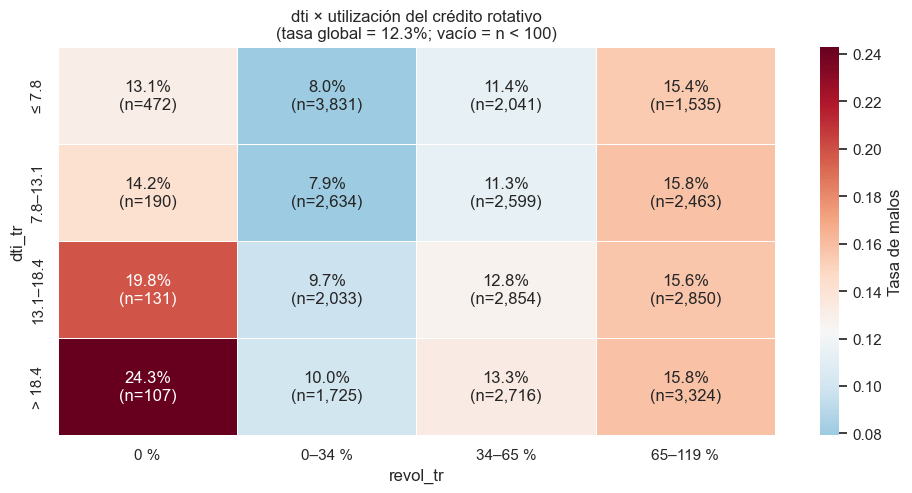

Tasa de malos (%):


revol_tr,0 %,0–34 %,34–65 %,65–119 %
dti_tr,,,,
≤ 7.8,13.1,8.0,11.4,15.4
7.8–13.1,14.2,7.9,11.3,15.8
13.1–18.4,19.8,9.7,12.8,15.6
> 18.4,24.3,10.0,13.3,15.8


Número de créditos:


revol_tr,0 %,0–34 %,34–65 %,65–119 %
dti_tr,,,,
≤ 7.8,472,3831,2041,1535
7.8–13.1,190,2634,2599,2463
13.1–18.4,131,2033,2854,2850
> 18.4,107,1725,2716,3324


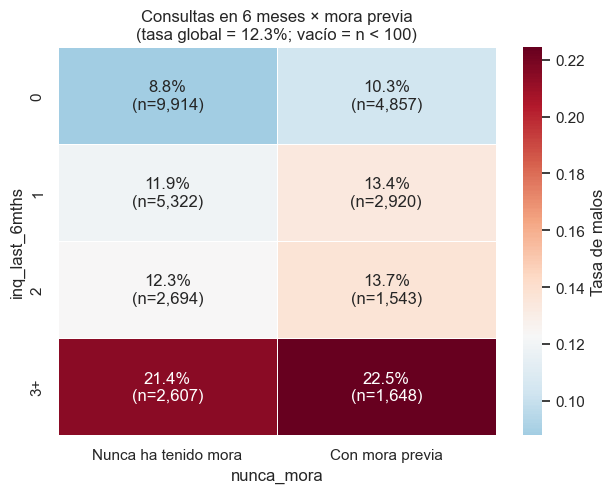

Tasa de malos (%):


nunca_mora,Nunca ha tenido mora,Con mora previa
inq_last_6mths,,
0,8.8,10.3
1,11.9,13.4
2,12.3,13.7
3+,21.4,22.5


Número de créditos:


nunca_mora,Nunca ha tenido mora,Con mora previa
inq_last_6mths,,
0,9914,4857
1,5322,2920
2,2694,1543
3+,2607,1648


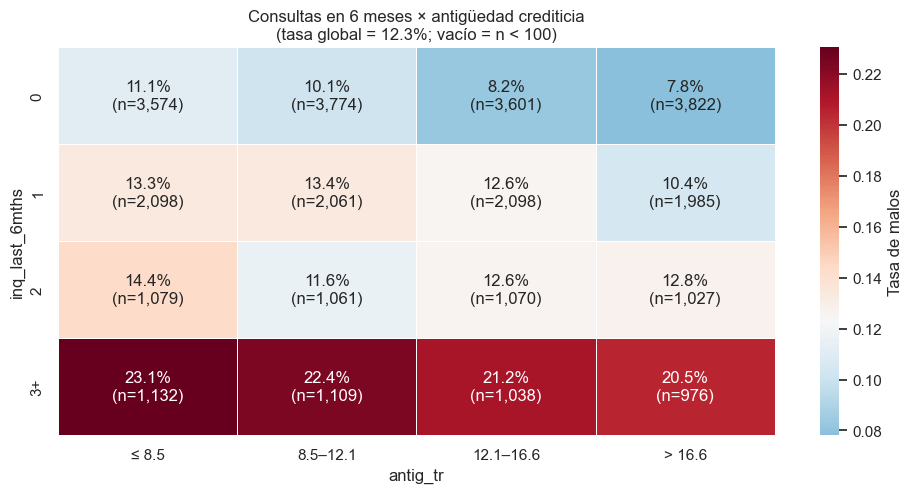

Tasa de malos (%):


antig_tr,≤ 8.5,8.5–12.1,12.1–16.6,> 16.6
inq_last_6mths,,,,
0,11.1,10.1,8.2,7.8
1,13.3,13.4,12.6,10.4
2,14.4,11.6,12.6,12.8
3+,23.1,22.4,21.2,20.5


Número de créditos:


antig_tr,≤ 8.5,8.5–12.1,12.1–16.6,> 16.6
inq_last_6mths,,,,
0,3574,3774,3601,3822
1,2098,2061,2098,1985
2,1079,1061,1070,1027
3+,1132,1109,1038,976


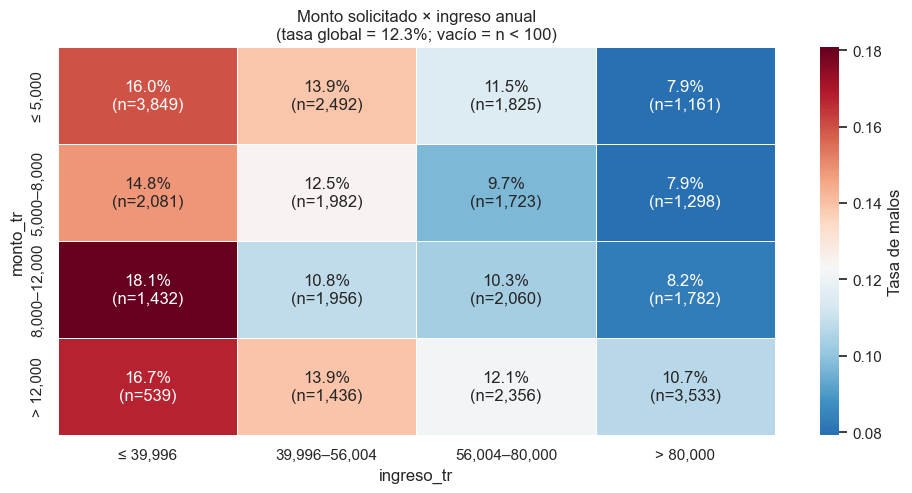

Tasa de malos (%):


ingreso_tr,"≤ 39,996","39,996–56,004","56,004–80,000","> 80,000"
monto_tr,,,,
"≤ 5,000",16.0,13.9,11.5,7.9
"5,000–8,000",14.8,12.5,9.7,7.9
"8,000–12,000",18.1,10.8,10.3,8.2
"> 12,000",16.7,13.9,12.1,10.7


Número de créditos:


ingreso_tr,"≤ 39,996","39,996–56,004","56,004–80,000","> 80,000"
monto_tr,,,,
"≤ 5,000",3849,2492,1825,1161
"5,000–8,000",2081,1982,1723,1298
"8,000–12,000",1432,1956,2060,1782
"> 12,000",539,1436,2356,3533


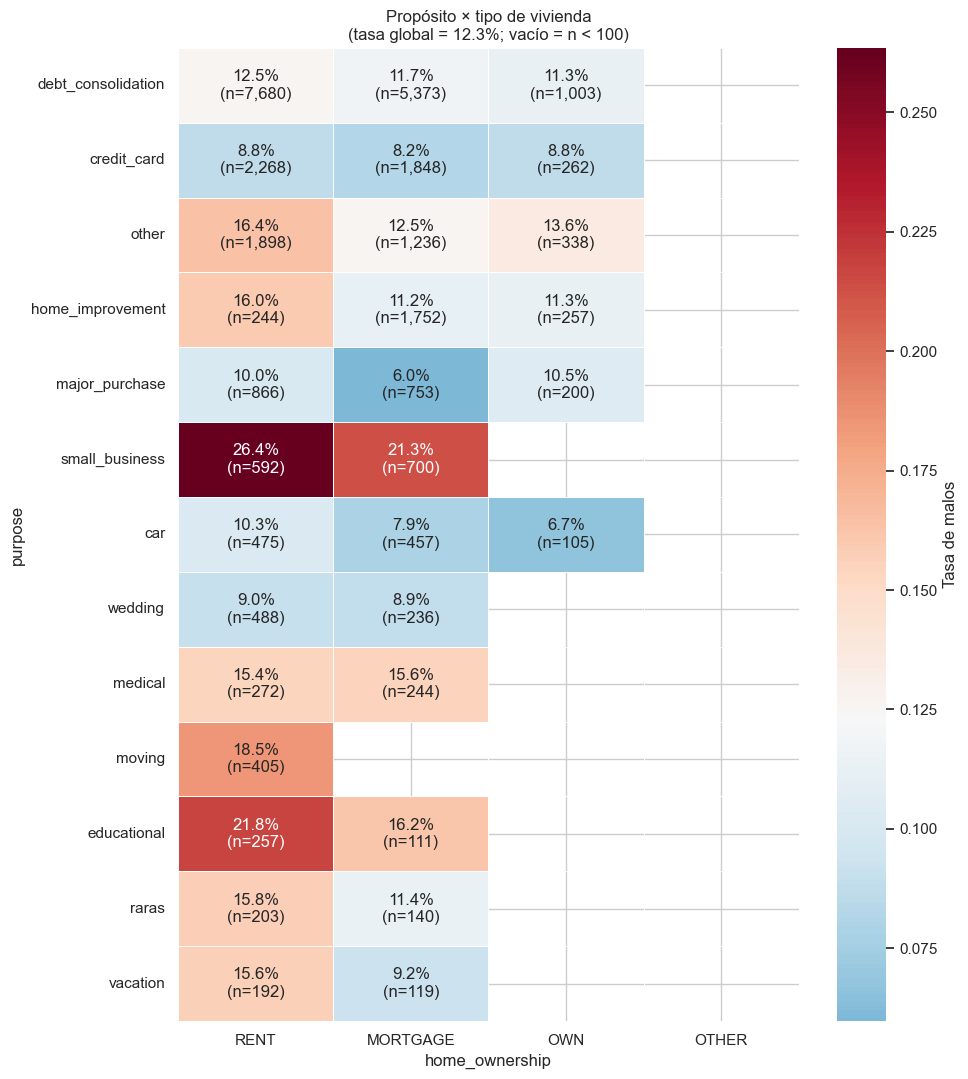

Tasa de malos (%):


home_ownership,RENT,MORTGAGE,OWN,OTHER
purpose,,,,
debt_consolidation,12.5,11.7,11.3,NaN
credit_card,8.8,8.2,8.8,NaN
other,16.4,12.5,13.6,NaN
home_improvement,16.0,11.2,11.3,NaN
major_purchase,10.0,6.0,10.5,NaN
small_business,26.4,21.3,NaN,NaN
car,10.3,7.9,6.7,NaN
wedding,9.0,8.9,NaN,NaN
medical,15.4,15.6,NaN,NaN


Número de créditos:


home_ownership,RENT,MORTGAGE,OWN,OTHER
purpose,,,,
debt_consolidation,7680,5373,1003,52
credit_card,2268,1848,262,16
other,1898,1236,338,22
home_improvement,244,1752,257,7
major_purchase,866,753,200,8
small_business,592,700,81,13
car,475,457,105,3
wedding,488,236,51,1
medical,272,244,57,5


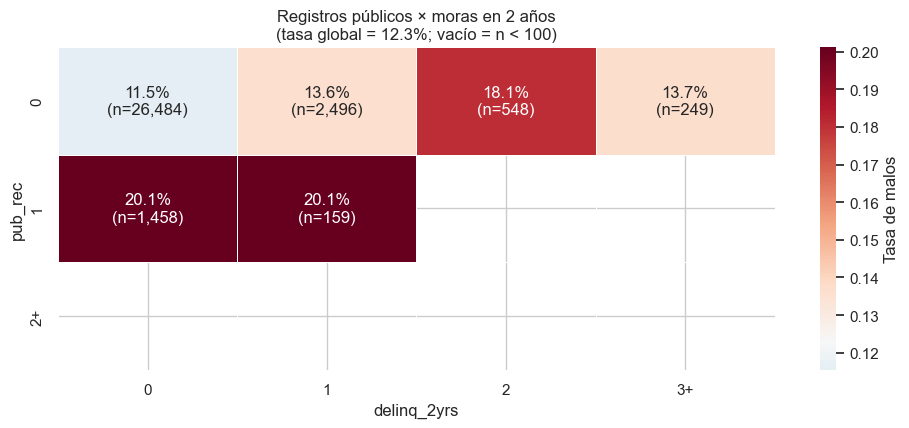

Tasa de malos (%):


delinq_2yrs,0,1,2,3+
pub_rec,,,,
0,11.5,13.6,18.1,13.7
1,20.1,20.1,NaN,NaN
2+,NaN,NaN,NaN,NaN


Número de créditos:


delinq_2yrs,0,1,2,3+
pub_rec,,,,
0,26484,2496,548,249
1,1458,159,33,14
2+,55,7,1,1


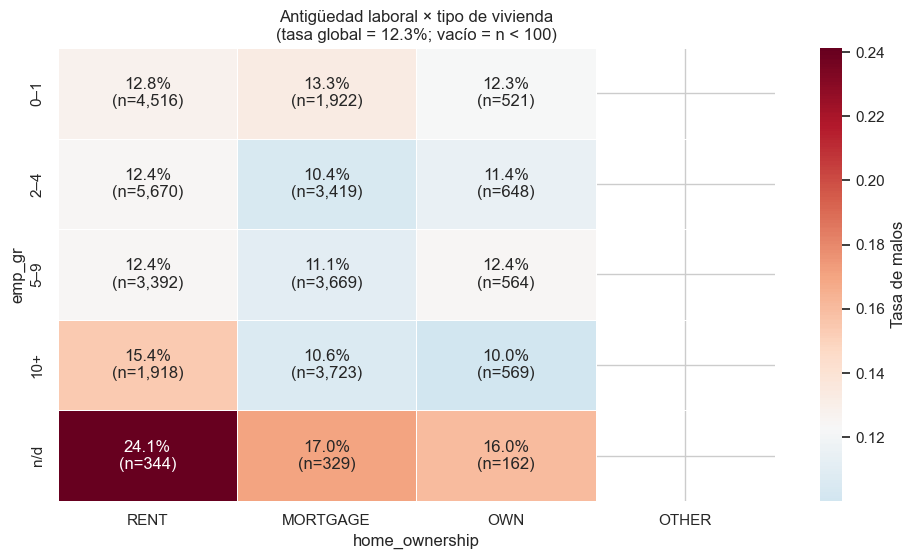

Tasa de malos (%):


home_ownership,RENT,MORTGAGE,OWN,OTHER
emp_gr,,,,
0–1,12.8,13.3,12.3,NaN
2–4,12.4,10.4,11.4,NaN
5–9,12.4,11.1,12.4,NaN
10+,15.4,10.6,10.0,NaN
n/d,24.1,17.0,16.0,NaN


Número de créditos:


home_ownership,RENT,MORTGAGE,OWN,OTHER
emp_gr,,,,
0–1,4516,1922,521,52
2–4,5670,3419,648,40
5–9,3392,3669,564,24
10+,1918,3723,569,23
n/d,344,329,162,0


In [71]:
# ====================================================================
# Tablas cruzadas: tasa de malos y n por combinacion de dos variables
# ====================================================================
def cruce(f, c, titulo, min_n=30):
    n = pd.crosstab(cat_df[f], cat_df[c])
    malos = pd.crosstab(cat_df[f], cat_df[c], values=cat_df["y"], aggfunc="sum").fillna(0)
    # orden: natural si es ordinal; si es nominal, por tamano
    of = ORDEN.get(f) or list(n.sum(axis=1).sort_values(ascending=False).index)
    oc = ORDEN.get(c) or list(n.sum(axis=0).sort_values(ascending=False).index)
    n = n.reindex(index=[i for i in of if i in n.index], columns=[j for j in oc if j in n.columns])
    malos = malos.reindex(index=n.index, columns=n.columns).fillna(0)
    tasa = (malos / n.replace(0, np.nan)).where(n >= min_n)

    txt = pd.DataFrame("", index=n.index, columns=n.columns)
    for i in n.index:
        for j in n.columns:
            if n.loc[i, j] >= min_n:
                txt.loc[i, j] = f"{tasa.loc[i, j]:.1%}\n(n={n.loc[i, j]:,})"

    fig, ax = plt.subplots(figsize=(1.7 * n.shape[1] + 3, 0.65 * n.shape[0] + 2.5))
    sns.heatmap(tasa.astype(float), annot=txt.values, fmt="", cmap="RdBu_r", center=tasa_global,
                linewidths=.5, linecolor="white", cbar_kws={"label": "Tasa de malos"}, ax=ax)
    ax.set_title(f"{titulo}\n(tasa global = {tasa_global:.1%}; vacío = n < {min_n})")
    ax.set_xlabel(c); ax.set_ylabel(f)
    plt.tight_layout(); plt.show()
    print("Tasa de malos (%):"); display((100 * tasa).round(1))
    print("Número de créditos:"); display(n)



cruce("dti_tr", "revol_tr", "dti × utilización del crédito rotativo", min_n=100)
cruce("inq_last_6mths", "nunca_mora", "Consultas en 6 meses × mora previa", min_n=100)
cruce("inq_last_6mths", "antig_tr", "Consultas en 6 meses × antigüedad crediticia", min_n=100)
cruce("monto_tr", "ingreso_tr", "Monto solicitado × ingreso anual", min_n=100)
cruce("purpose", "home_ownership", "Propósito × tipo de vivienda", min_n=100)
cruce("pub_rec", "delinq_2yrs", "Registros públicos × moras en 2 años", min_n=100)
cruce("emp_gr", "home_ownership", "Antigüedad laboral × tipo de vivienda", min_n=100)

### Gráficos

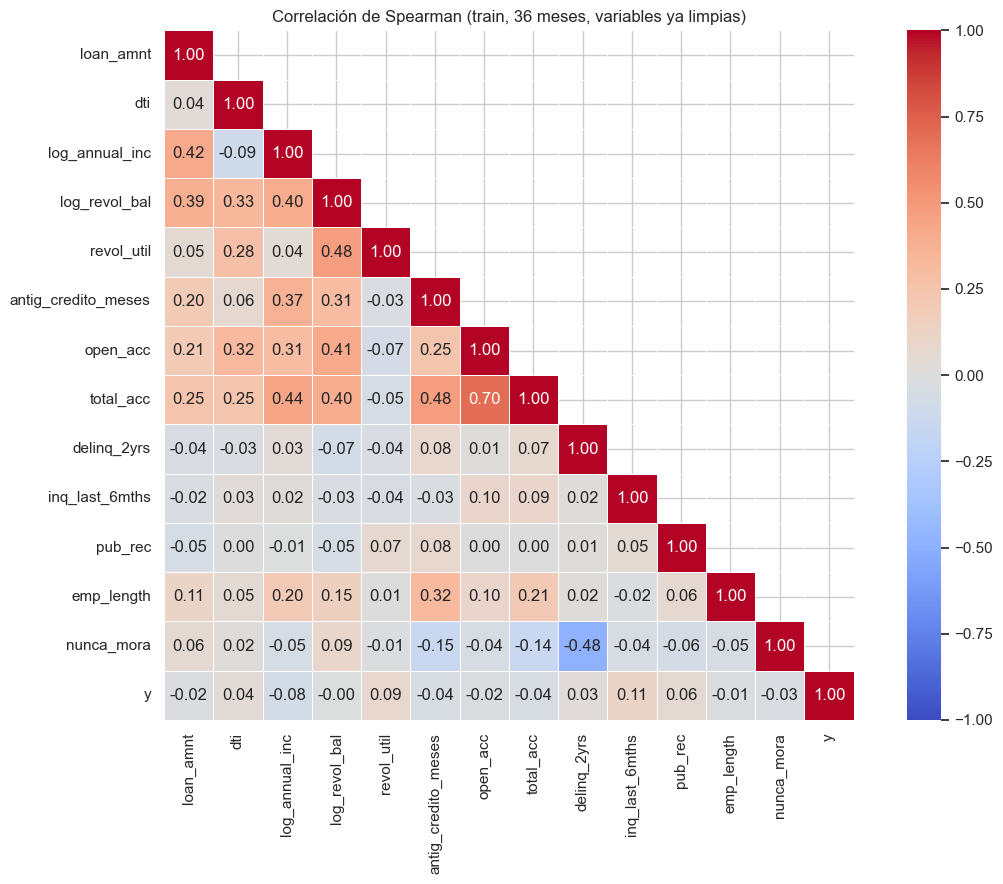

In [55]:
# Datos para graficar: limpios, sin escalar, solo train, con y
plot_df = X_train_raw.join(train_a["y"])      # mismo indice, y alineado fila a fila

var_cont = ["loan_amnt", "dti", "log_annual_inc", "log_revol_bal", "revol_util",
            "antig_credito_meses", "open_acc", "total_acc"]
var_disc = ["delinq_2yrs", "inq_last_6mths", "pub_rec", "emp_length"]

# ---------- 1) Matriz de correlacion (Spearman) ----------
cols_corr = var_cont + var_disc + ["nunca_mora", "y"]
corr = plot_df[cols_corr].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # solo triangulo inferior

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Correlación de Spearman (train, 36 meses, variables ya limpias)")
plt.tight_layout(); plt.show()

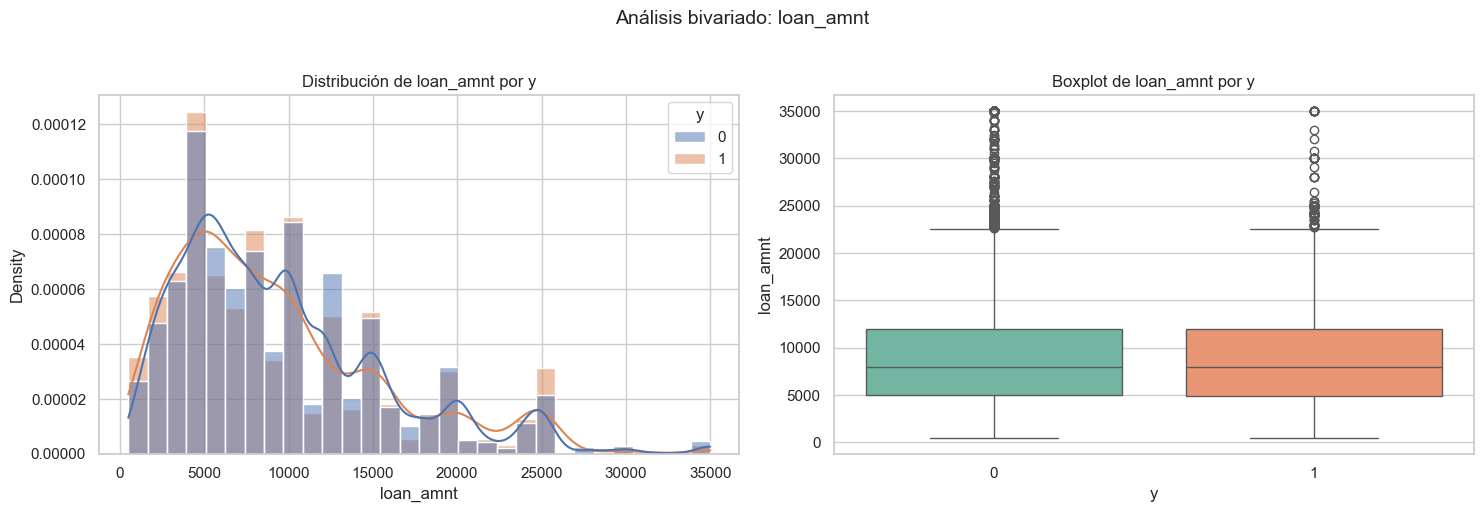

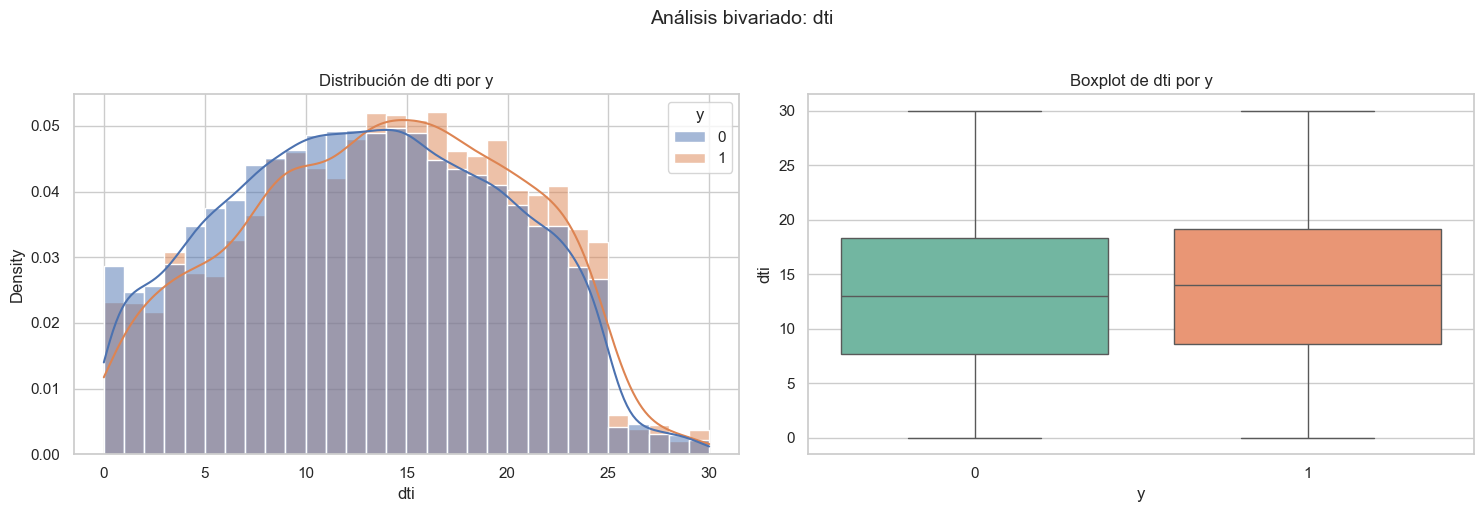

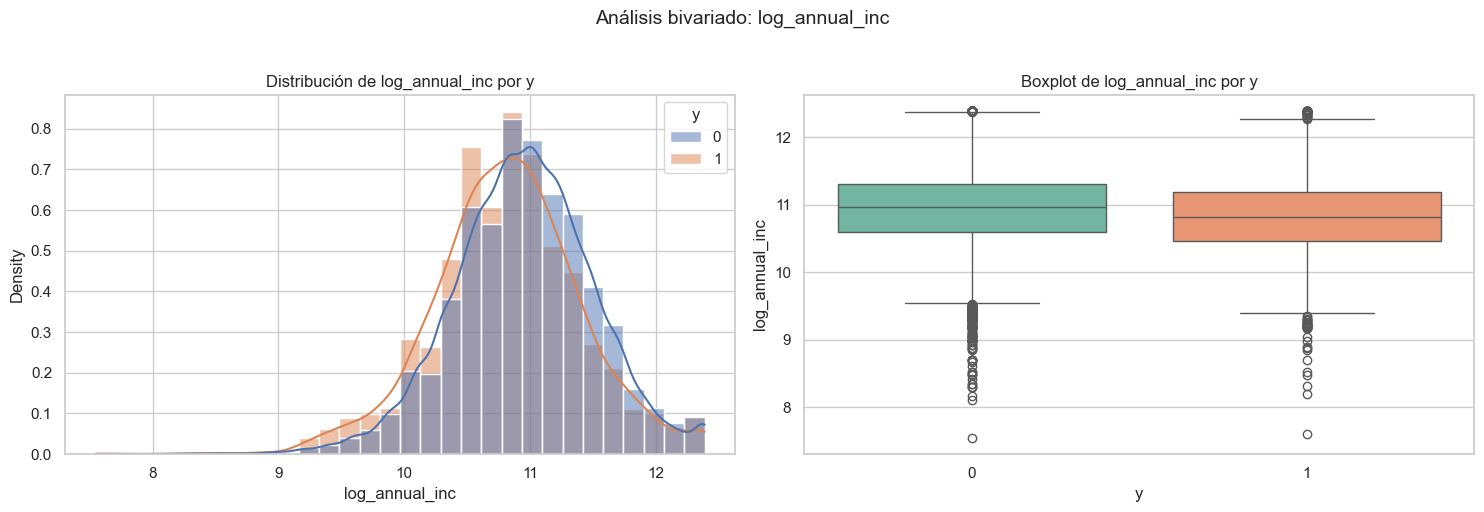

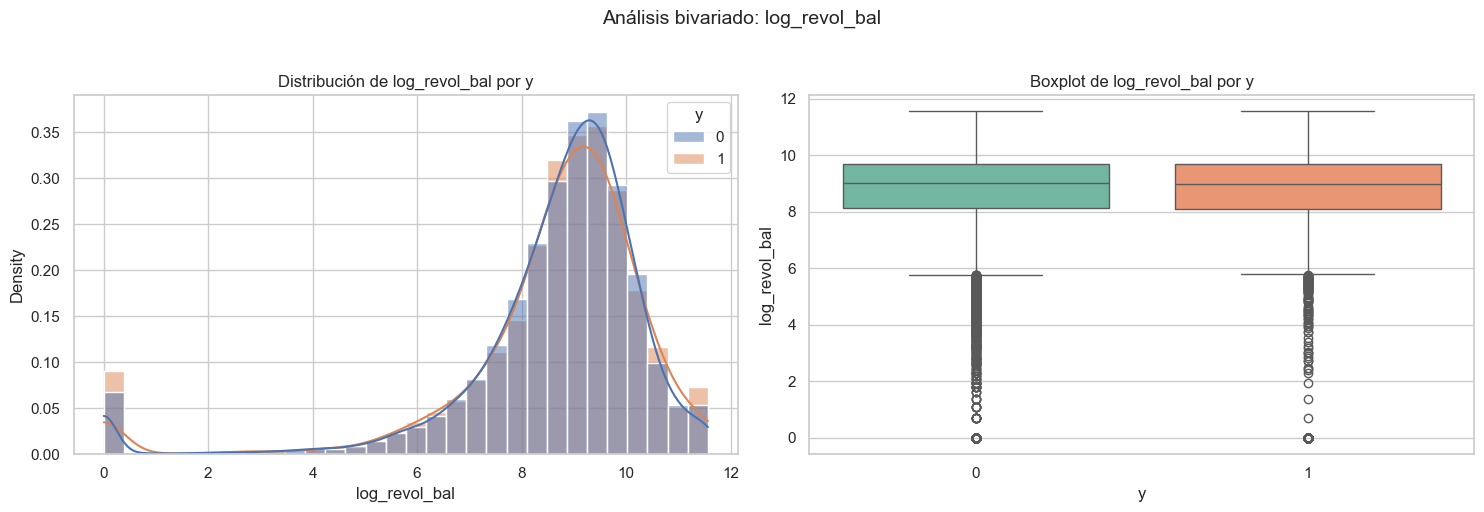

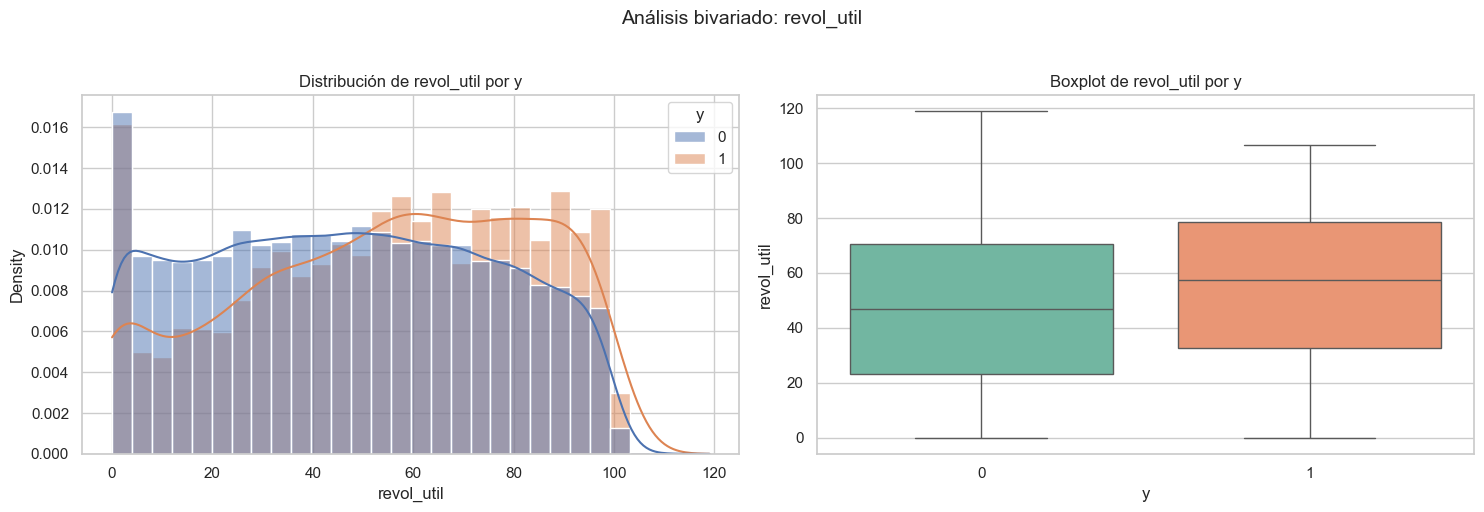

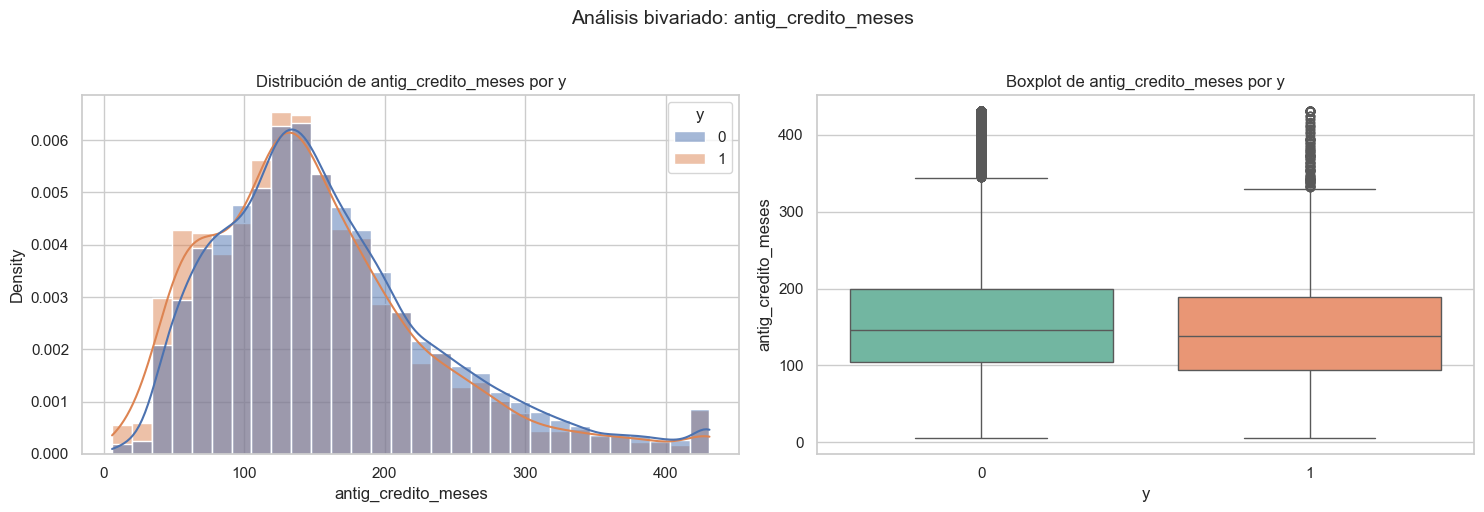

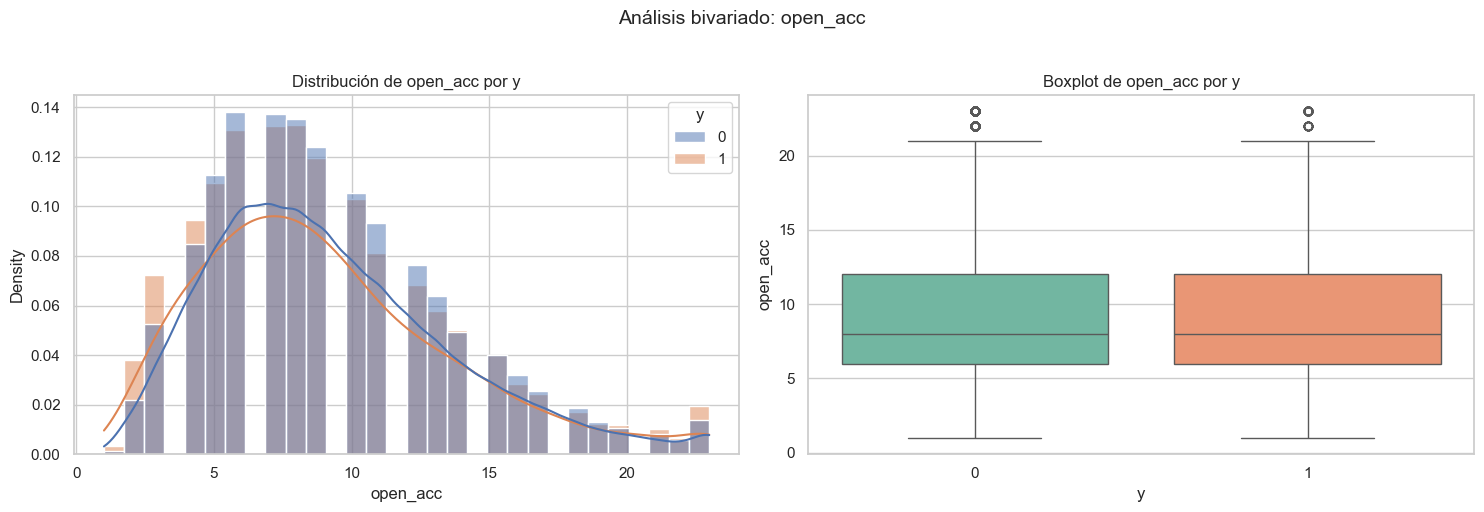

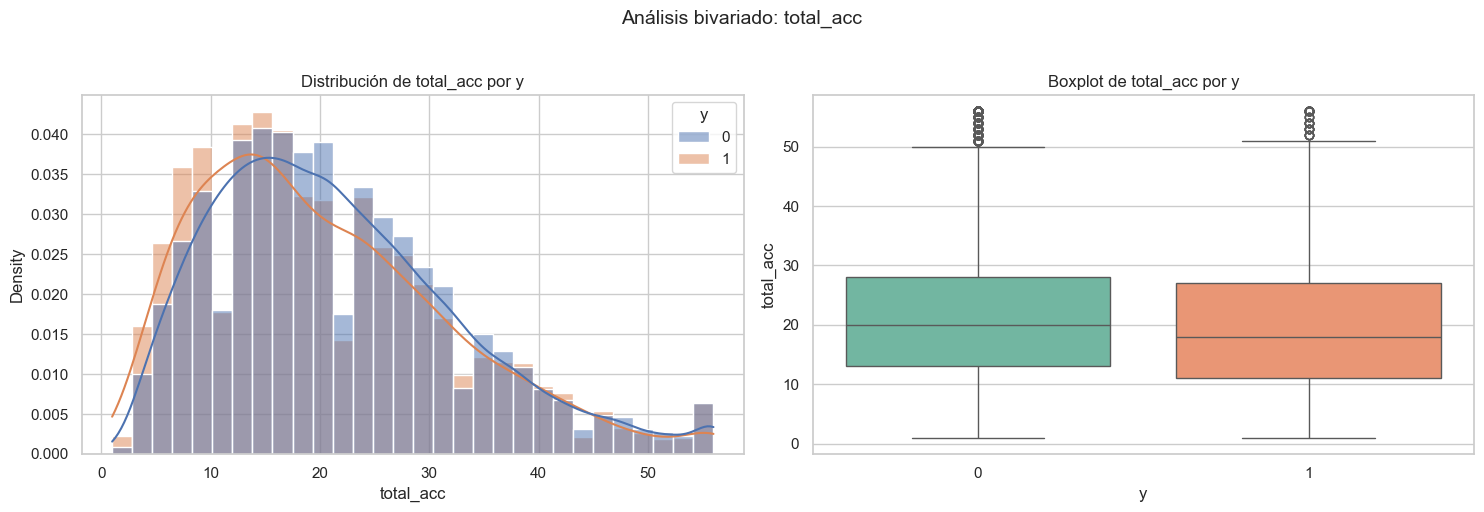

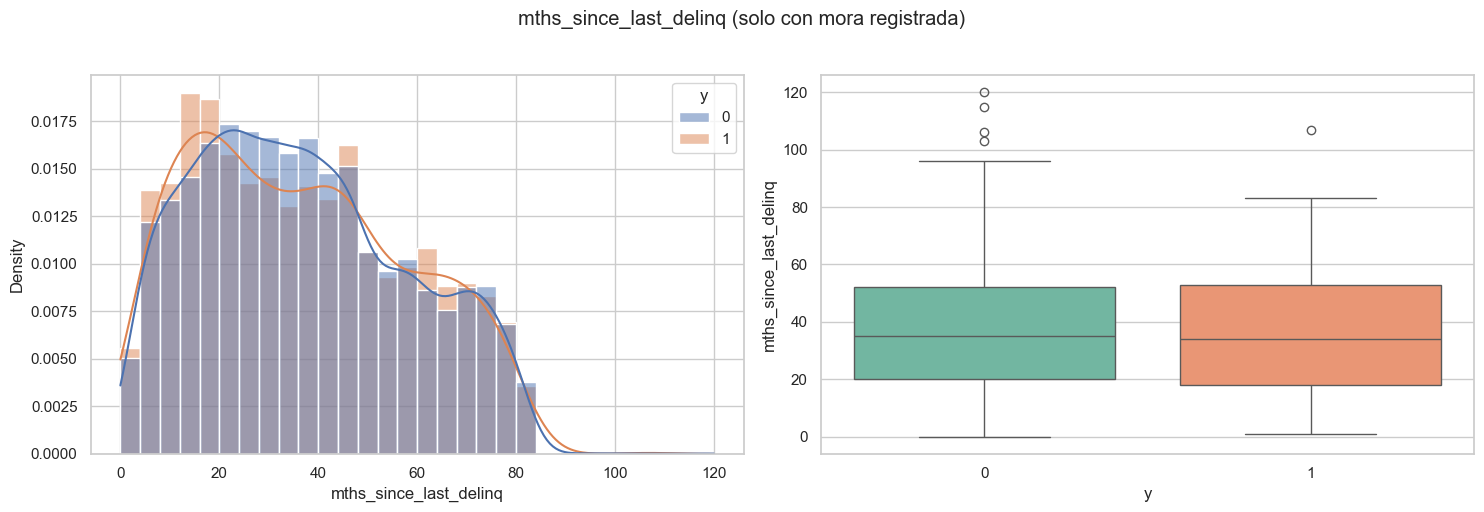

In [56]:
# ---------- 2) Continuas: histograma de densidad + boxplot por y ----------
sns.set_theme(style="whitegrid")
for col in var_cont:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.histplot(data=plot_df, x=col, hue="y", kde=True, stat="density",
                 common_norm=False, bins=30, ax=axes[0], alpha=0.5)
    axes[0].set_title(f"Distribución de {col} por y")
    sns.boxplot(data=plot_df, x="y", y=col, hue="y", palette="Set2", legend=False, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col} por y")
    plt.suptitle(f"Análisis bivariado: {col}", fontsize=14, y=1.02)
    plt.tight_layout(); plt.show()

# mths_since_last_delinq: solo valores observados (quienes alguna vez tuvieron mora)
obs = train_a.loc[train_a["nunca_mora"] == 0, ["mths_since_last_delinq", "y"]]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=obs, x="mths_since_last_delinq", hue="y", kde=True, stat="density",
             common_norm=False, bins=30, ax=axes[0], alpha=0.5)
sns.boxplot(data=obs, x="y", y="mths_since_last_delinq", hue="y", palette="Set2", legend=False, ax=axes[1])
plt.suptitle("mths_since_last_delinq (solo con mora registrada)", y=1.02)
plt.tight_layout(); plt.show()

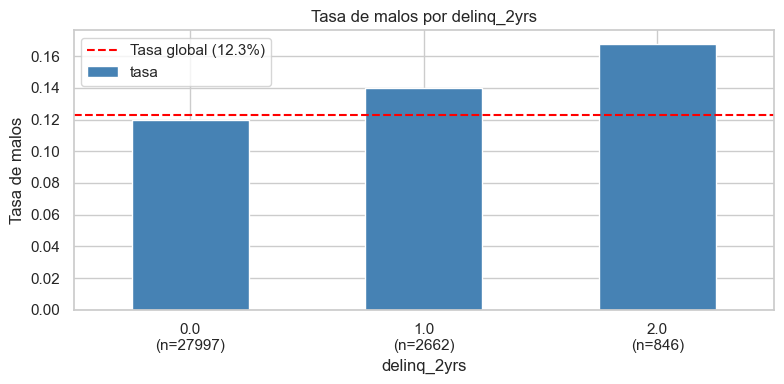

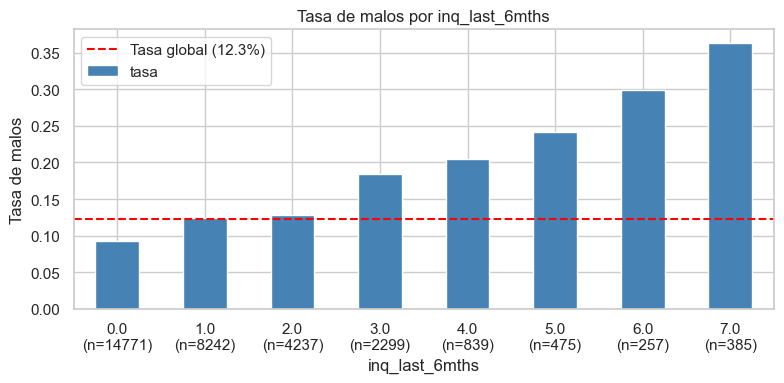

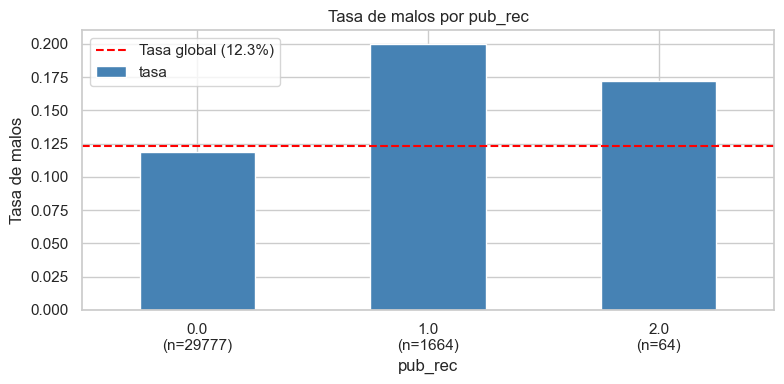

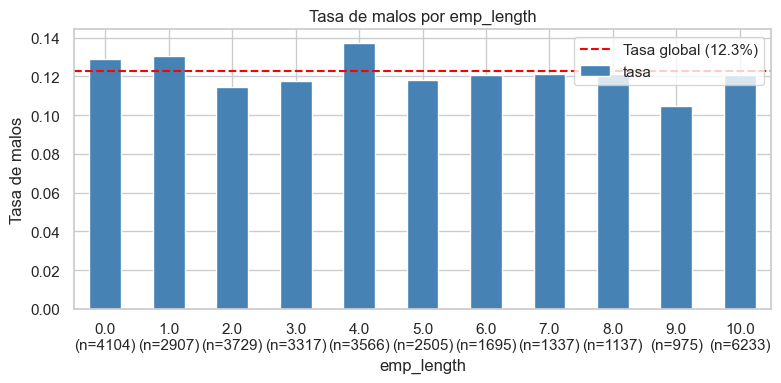

In [57]:
# ---------- 3) Discretas: tasa de malos por categoria ----------
tasa_global = plot_df["y"].mean()
for col in var_disc:
    g = plot_df.groupby(col)["y"].agg(tasa="mean", n="size")
    ax = g["tasa"].plot(kind="bar", figsize=(8, 4), color="steelblue")
    ax.axhline(tasa_global, color="red", linestyle="--", label=f"Tasa global ({tasa_global:.1%})")
    ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(g.index, g["n"])], rotation=0)
    ax.set_ylabel("Tasa de malos"); ax.set_title(f"Tasa de malos por {col}")
    ax.legend(); plt.tight_layout(); plt.show()

## hipótesis sobre qué hace más riesgosa a una persona

1. Consultas recientes. A mayor número de consultas crediticias en los últimos 6 meses (inq_last_6mths), mayor probabilidad de que el crédito sea malo.

2. Ingreso. A menor ingreso anual (annual_inc), mayor probabilidad de que el crédito sea malo, tanto en términos marginales como al controlar por las demás variables.

3. Uso del crédito rotativo. A mayor utilización (revol_util), mayor probabilidad de que el crédito sea malo entre quienes usan crédito rotativo.

4. Antigüedad del historial. A mayor antigüedad del historial crediticio (antig_credito_meses), menor probabilidad de que el crédito sea malo.

5. Endeudamiento. A mayor dti, mayor probabilidad de que el crédito sea malo.

# Modelo de referencia: Regresión logística 

In [61]:
EPS = 1e-12
MAX_ITER = 5000
CS = np.logspace(-4, 2, 13)            # rejilla de C: 1e-4 ... 1e2 (13 valores)
PENALIZACIONES = ["l2", "l1"]          # L2 = principal (decidido antes de ver resultados); L1 = comparacion
TOL_EMPATE = 1e-4                      # desempate fijado a priori: ver Celda 2

y_tr, y_va, y_te = y_train.to_numpy(), y_valid.to_numpy(), y_test.to_numpy()
pi_train = y_tr.mean()                 # tasa de malos de entrenamiento = predictor constante de referencia
n_train = len(y_tr)

# scikit-learn >= 1.8 reemplazo `penalty` por `l1_ratio` (0 = L2, 1 = L1)
API_NUEVA = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)

def crea_logit(pen, C):
    solver = "lbfgs" if pen == "l2" else "saga"     # lbfgs no penaliza el intercepto
    if API_NUEVA:
        return LogisticRegression(C=C, l1_ratio=0.0 if pen == "l2" else 1.0,
                                  solver=solver, max_iter=MAX_ITER)
    return LogisticRegression(penalty=pen, C=C, solver=solver, max_iter=MAX_ITER)

def logit_seguro(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p))

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def calibracion_lineal(y, p):
    """Intercepto y pendiente de logit(P(y=1)) = a + b*logit(p_hat), y 'shift' con pendiente fija en 1."""
    z = logit_seguro(p)
    mod = sm.Logit(y, sm.add_constant(z)).fit(disp=0)
    glm = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(), offset=z).fit()
    return {"intercepto": float(mod.params[0]), "pendiente": float(mod.params[1]),
            "shift": float(glm.params[0])}

def metricas(y, p, pi_ref=pi_train):
    auc = roc_auc_score(y, p)
    brier = brier_score_loss(y, p)
    brier_ref = float(np.mean((pi_ref - y) ** 2))     # predictor constante = tasa de entrenamiento
    cal = calibracion_lineal(y, p)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(y, p),
            "Brier": brier, "Brier_ref": brier_ref, "BSS": 1 - brier / brier_ref,
            "LogLoss": log_loss(y, p), "media_pred": float(np.mean(p)), "tasa_obs": float(np.mean(y)),
            "cal_intercepto": cal["intercepto"], "cal_pendiente": cal["pendiente"], "cal_shift": cal["shift"]}

def tabla_calibracion(y, p, n_bins=10):
    d = pd.DataFrame({"y": y, "p": p})
    d["bin"] = pd.qcut(d["p"], n_bins, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(p_media=("p", "mean"), tasa_obs=("y", "mean"),
                                            n=("y", "size"), malos=("y", "sum")).reset_index(drop=True)
    lo, hi = proportion_confint(g["malos"].to_numpy(), g["n"].to_numpy(), alpha=0.05, method="wilson")
    g["ic_inf"], g["ic_sup"] = lo, hi
    return g

def graficos_evaluacion(y, p, titulo):
    """ROC con AUC y KS, curva de calibracion con IC de Wilson y histograma de las probabilidades."""
    tabla = tabla_calibracion(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y, p):.3f} | KS = {np.max(tpr - fpr):.3f}")
    ax[0].plot([0, 1], [0, 1], "--", color="grey")
    ax[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curva ROC")
    ax[0].legend(loc="lower right")
    lim = float(max(tabla["p_media"].max(), tabla["ic_sup"].max())) * 1.05
    ax[1].plot([0, lim], [0, lim], "--", color="grey", label="Calibración perfecta")
    ax[1].errorbar(tabla["p_media"], tabla["tasa_obs"],
                   yerr=[tabla["tasa_obs"] - tabla["ic_inf"], tabla["ic_sup"] - tabla["tasa_obs"]],
                   fmt="o-", capsize=3, label="Deciles de la probabilidad predicha (IC 95 %)")
    ax[1].set(xlabel="Probabilidad predicha (media del decil)", ylabel="Tasa observada de malos",
              title="Curva de calibración")
    ax[1].legend(loc="upper left")
    ax[2].hist(p, bins=40, color="steelblue")
    ax[2].set(xlabel="Probabilidad predicha", ylabel="Frecuencia", title="Distribución de las probabilidades")
    fig.suptitle(titulo, fontsize=13, y=1.02)
    plt.tight_layout(); plt.show()
    return tabla

def auc_por_trimestre(y, p, fechas):
    d = pd.DataFrame({"y": y, "p": p, "t": pd.Series(fechas).dt.to_period("Q").to_numpy()})
    filas = [{"trimestre": str(t), "n": len(g), "tasa_obs": g["y"].mean(),
              "media_pred": g["p"].mean(), "AUC": roc_auc_score(g["y"], g["p"])}
             for t, g in d.groupby("t")]
    return pd.DataFrame(filas)


Configuraciones evaluadas (presupuesto de busqueda): 26
C elegido  L2 (modelo principal): 0.01 | L1 (comparacion): 0.03162
penalizacion         C  lambda  logloss_train  logloss_valid  brier_valid  auc_valid  coef_no_cero  n_iter  convergio
          l2   0.00010 0.31741        0.36426        0.39694      0.11795    0.61812            30       8       True
          l2   0.00032 0.10037        0.35828        0.39318      0.11708    0.62485            30       8       True
          l2   0.00100 0.03174        0.35399        0.39005      0.11631    0.63210            30      12       True
          l2   0.00316 0.01004        0.35134        0.38824      0.11582    0.63636            30      14       True
          l2   0.01000 0.00317        0.34974        0.38788      0.11567    0.63671            30      22       True
          l2   0.03162 0.00100        0.34910        0.38824      0.11573    0.63543            30      25       True
          l2   0.10000 0.00032        0.34893      

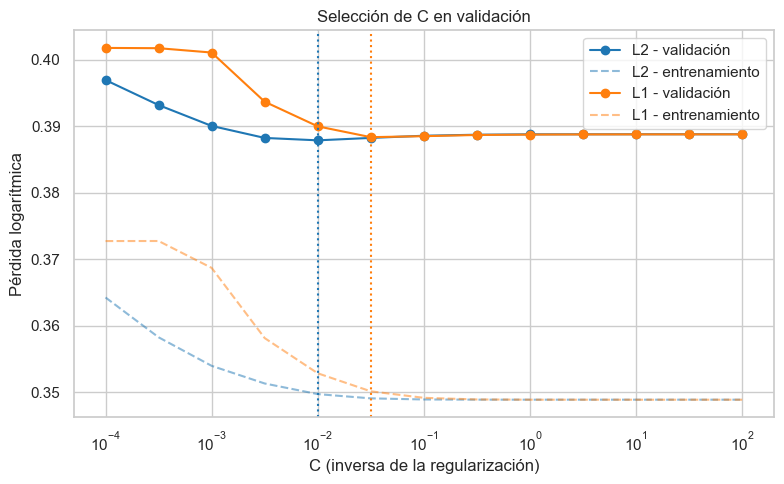

In [ ]:
# ====================================================================
# Seleccion de C con VALIDACION (los modelos se ajustan solo con train)
# =========================================================================
modelos, filas = {}, []
for pen in PENALIZACIONES:
    for C in CS:
        m = crea_logit(pen, C).fit(X_train, y_tr)
        p_tr = m.predict_proba(X_train)[:, 1]
        p_va = m.predict_proba(X_valid)[:, 1]
        modelos[(pen, C)] = m
        filas.append({"penalizacion": pen, "C": C, "lambda": 1 / (C * n_train),
                      "logloss_train": log_loss(y_tr, p_tr), "logloss_valid": log_loss(y_va, p_va),
                      "brier_valid": brier_score_loss(y_va, p_va), "auc_valid": roc_auc_score(y_va, p_va),
                      "coef_no_cero": int(np.sum(np.abs(m.coef_) > 1e-8)),
                      "n_iter": int(np.max(m.n_iter_)), "convergio": bool(np.max(m.n_iter_) < MAX_ITER)})
res = pd.DataFrame(filas)
print(f"Configuraciones evaluadas (presupuesto de busqueda): {len(res)}")
assert res["convergio"].all(), "Algun ajuste no convergio: sube MAX_ITER o revisa la escala de las variables"

def elige_C(pen):
    r = res[res["penalizacion"] == pen]
    candidatas = r[r["logloss_valid"] <= r["logloss_valid"].min() + TOL_EMPATE]
    return float(candidatas["C"].min())

C_l2, C_l1 = elige_C("l2"), elige_C("l1")
print(f"C elegido  L2 (modelo principal): {C_l2:.4g} | L1 (comparacion): {C_l1:.4g}")
print(res.round(5).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
for pen, color in [("l2", "tab:blue"), ("l1", "tab:orange")]:
    r = res[res["penalizacion"] == pen]
    ax.plot(r["C"], r["logloss_valid"], "o-", color=color, label=f"{pen.upper()} - validación")
    ax.plot(r["C"], r["logloss_train"], "--", color=color, alpha=0.5, label=f"{pen.upper()} - entrenamiento")
ax.axvline(C_l2, color="tab:blue", ls=":"); ax.axvline(C_l1, color="tab:orange", ls=":")
ax.set_xscale("log"); ax.set_xlabel("C (inversa de la regularización)"); ax.set_ylabel("Pérdida logarítmica")
ax.set_title("Selección de C en validación"); ax.legend(); plt.tight_layout(); plt.show()

modelo = modelos[("l2", C_l2)]          # MODELO PRINCIPAL (congelado a partir de aqui)

                 train  valid (usada para seleccion)
AUC             0.6808                        0.6367
Gini            0.3616                        0.2734
KS              0.2618                        0.1954
Brier           0.1024                        0.1157
Brier_ref       0.1078                        0.1191
BSS             0.0499                        0.0285
LogLoss         0.3497                        0.3879
media_pred      0.1229                        0.1216
tasa_obs        0.1229                        0.1378
cal_intercepto  0.1709                        0.2213
cal_pendiente   1.0930                        1.0385
cal_shift       0.0002                        0.1481


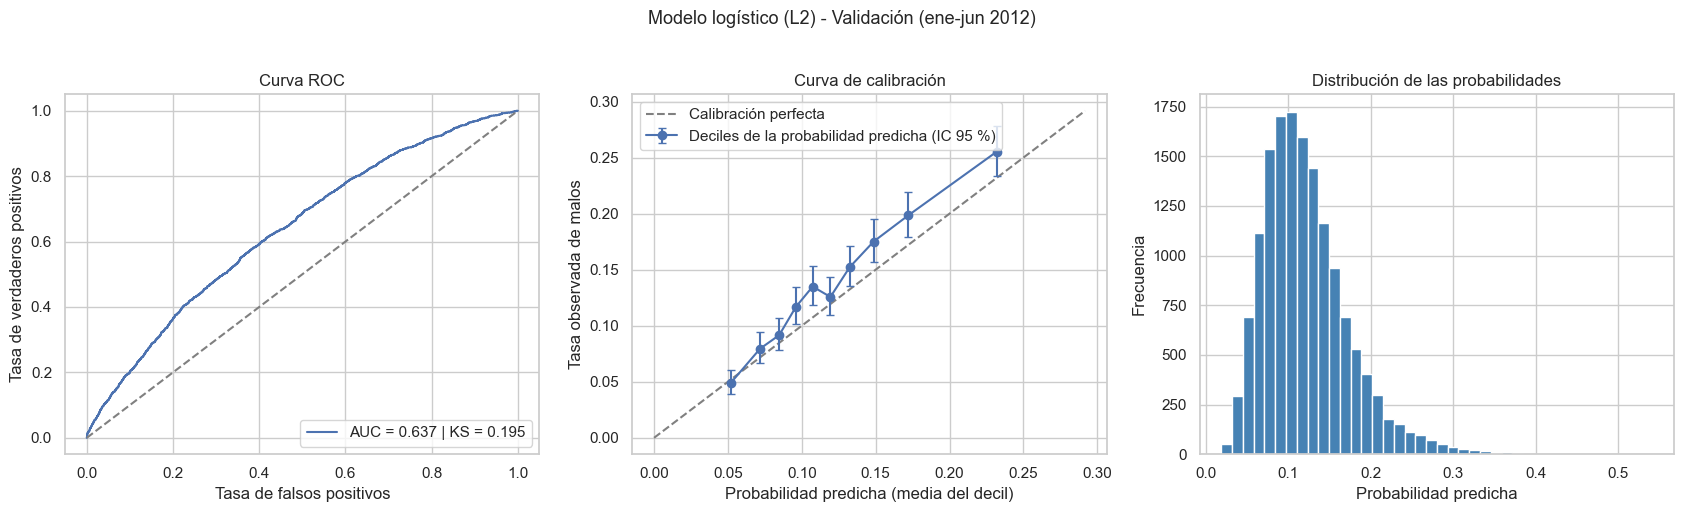

   p_media  tasa_obs     n  malos  ic_inf  ic_sup
0   0.0518    0.0488  1497     73  0.0390  0.0609
1   0.0717    0.0795  1497    119  0.0668  0.0943
2   0.0847    0.0916  1496    137  0.0780  0.1073
3   0.0960    0.1169  1497    175  0.1016  0.1342
4   0.1074    0.1349  1497    202  0.1186  0.1532
5   0.1194    0.1257  1496    188  0.1098  0.1434
6   0.1324    0.1523  1497    228  0.1350  0.1714
7   0.1486    0.1751  1496    262  0.1567  0.1952
8   0.1720    0.1984  1497    297  0.1790  0.2194
9   0.2318    0.2552  1497    382  0.2337  0.2779

AUC por trimestre en validacion:
  trimestre     n  tasa_obs  media_pred     AUC
0    2012Q1  6498    0.1320      0.1202  0.6272
1    2012Q2  8469    0.1423      0.1227  0.6430


In [ ]:
# ====================================================================
# Desempeno en ENTRENAMIENTO y VALIDACION (la validacion se uso para elegir C
# =============================================================================
p_tr = modelo.predict_proba(X_train)[:, 1]
p_va = modelo.predict_proba(X_valid)[:, 1]
tabla_metricas = pd.DataFrame({"train": metricas(y_tr, p_tr), "valid (usada para seleccion)": metricas(y_va, p_va)})
print(tabla_metricas.round(4).to_string())

tab_cal_va = graficos_evaluacion(y_va, p_va, "Modelo logístico (L2) - Validación (ene-jun 2012)")
print(tab_cal_va.round(4))
print("\nAUC por trimestre en validacion:")
print(auc_por_trimestre(y_va, p_va, valid_a["issue_date"]).round(4))

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                31505
Model:                          Logit   Df Residuals:                    31474
Method:                           MLE   Df Model:                           30
Date:               lun, 26 oct. 2026   Pseudo R-squ.:                 0.06393
Time:                        18:51:59   Log-Likelihood:                -10992.
converged:                       True   LL-Null:                       -11743.
Covariance Type:            nonrobust   LLR p-value:                1.914e-297
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -2.1398      0.045    -47.373      0.000      -2.228      -2.051
loan_amnt                    0.1610      0.021      7.650      0.000       0.120       0.

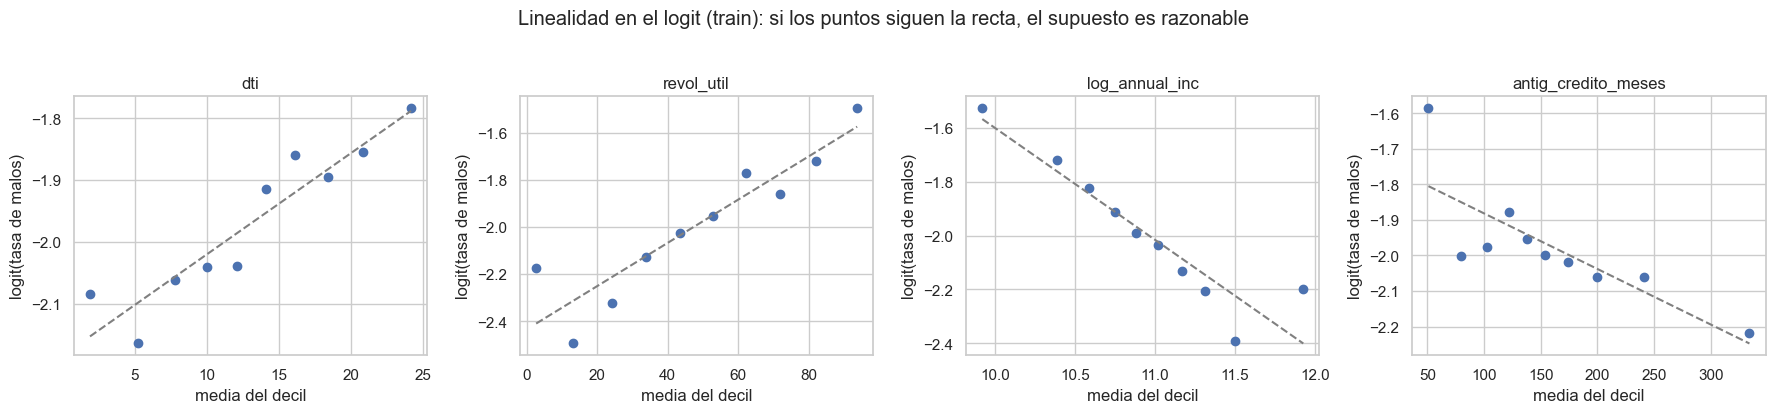

In [64]:
# ====================================================================
# Interpretacion: regresion logistica SIN penalizar (statsmodels) para odds ratios e IC
# =============================================================================
Xc = sm.add_constant(X_train.astype(float))
logit_sm = sm.Logit(y_tr, Xc).fit(disp=0, maxiter=200)
assert logit_sm.mle_retvals["converged"], "statsmodels no convergio"
print(logit_sm.summary())

ic = logit_sm.conf_int()
tabla_or = pd.DataFrame({"coef": logit_sm.params, "OR": np.exp(logit_sm.params),
                         "OR_inf95": np.exp(ic[0]), "OR_sup95": np.exp(ic[1]),
                         "p_valor": logit_sm.pvalues}).drop(index="const")
print("\nOdds ratios (variables numericas: por 1 desviacion estandar; dummies: frente a la categoria de referencia)")
print(tabla_or.sort_values("p_valor").round(4))

vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                index=X_train.columns, name="VIF")
print("\nFactores de inflacion de la varianza (VIF):")
print(vif.sort_values(ascending=False).round(2))

# Linealidad en el logit: tasa de malos por decil (escala logit) frente al valor medio de la variable
var_lin = ["dti", "revol_util", "log_annual_inc", "antig_credito_meses"]
fig, ax = plt.subplots(1, len(var_lin), figsize=(18, 4))
for a, v in zip(ax, var_lin):
    d = pd.DataFrame({"x": X_train_raw[v].to_numpy(), "y": y_tr})
    d["dec"] = pd.qcut(d["x"], 10, duplicates="drop")
    g = d.groupby("dec", observed=True).agg(x=("x", "mean"), tasa=("y", "mean"))
    lg = np.log(g["tasa"] / (1 - g["tasa"]))
    a.plot(g["x"], lg, "o")
    pend, ord_ = np.polyfit(g["x"], lg, 1)
    a.plot(g["x"], ord_ + pend * g["x"], "--", color="grey")
    a.set(title=v, xlabel="media del decil", ylabel="logit(tasa de malos)")
plt.suptitle("Linealidad en el logit (train): si los puntos siguen la recta, el supuesto es razonable", y=1.03)
plt.tight_layout(); plt.show()

Modelo principal (L2) en PRUEBA:
AUC               0.6284
Gini              0.2567
KS                0.1887
Brier             0.1151
Brier_ref         0.1178
BSS               0.0229
LogLoss           0.3866
media_pred        0.1257
tasa_obs          0.1361
cal_intercepto    0.0696
cal_pendiente     0.9870
cal_shift         0.0940
dtype: float64


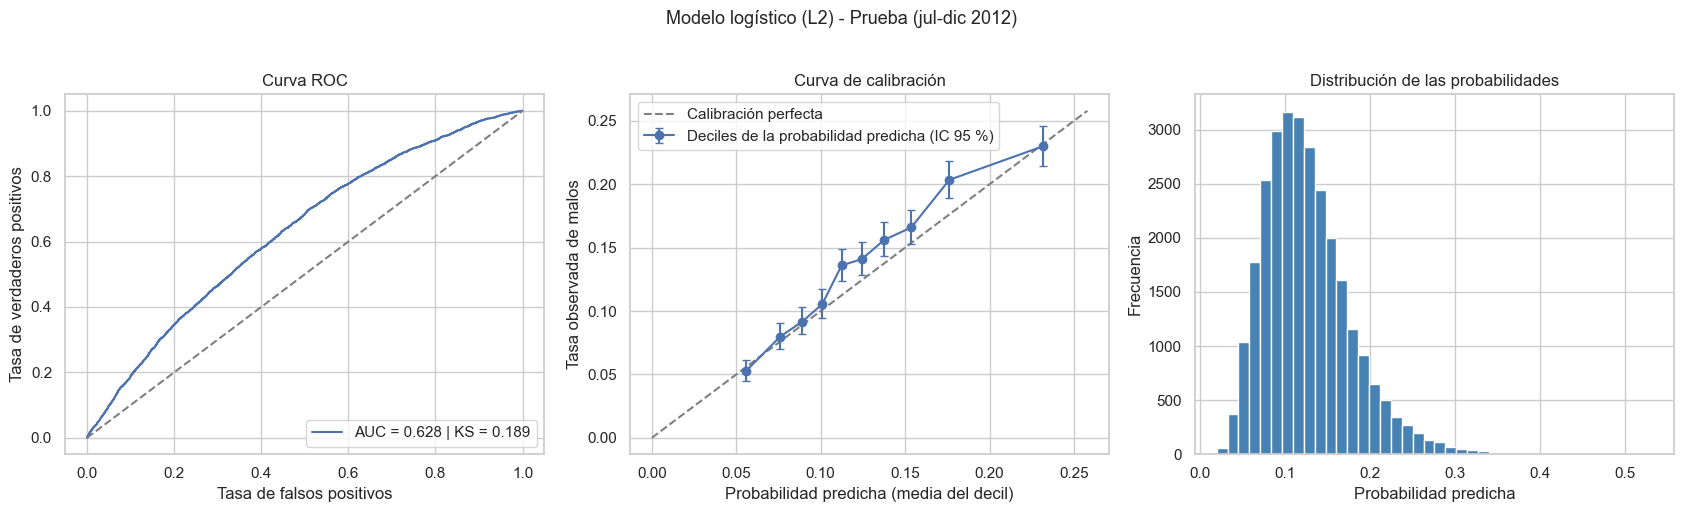

   p_media  tasa_obs     n  malos  ic_inf  ic_sup
0   0.0555    0.0524  2846    149  0.0448  0.0612
1   0.0760    0.0798  2846    227  0.0704  0.0903
2   0.0891    0.0917  2846    261  0.0816  0.1029
3   0.1009    0.1054  2845    300  0.0947  0.1173
4   0.1124    0.1360  2846    387  0.1239  0.1491
5   0.1244    0.1409  2846    401  0.1286  0.1542
6   0.1376    0.1561  2845    444  0.1432  0.1699
7   0.1536    0.1658  2846    472  0.1526  0.1800
8   0.1762    0.2034  2846    579  0.1891  0.2186
9   0.2314    0.2298  2846    654  0.2147  0.2456

AUC por trimestre en prueba:
  trimestre      n  tasa_obs  media_pred     AUC
0    2012Q3  13322    0.1422      0.1246  0.6386
1    2012Q4  15136    0.1308      0.1267  0.6193


In [65]:
# ====================================================================
# EVALUACION FINAL EN PRUEBA
# =============================================================================
p_te = modelo.predict_proba(X_test)[:, 1]
met_te = metricas(y_te, p_te)
print("Modelo principal (L2) en PRUEBA:")
print(pd.Series(met_te).round(4))

tab_cal_te = graficos_evaluacion(y_te, p_te, "Modelo logístico (L2) - Prueba (jul-dic 2012)")
print(tab_cal_te.round(4))
print("\nAUC por trimestre en prueba:")
print(auc_por_trimestre(y_te, p_te, test_a["issue_date"]).round(4))

In [66]:
# Comparacion
comparacion = {"L2 elegido (principal)": modelo,
               "L1 elegido": modelos[("l1", C_l1)],
               "Casi sin regularizar (L2, C=100)": modelos[("l2", float(CS[-1]))]}
filas = {}
for nombre, m in comparacion.items():
    filas[nombre] = metricas(y_te, m.predict_proba(X_test)[:, 1])
print("\nComparacion en prueba:")
print(pd.DataFrame(filas).round(4).to_string())


Comparacion en prueba:
                L2 elegido (principal)  L1 elegido  Casi sin regularizar (L2, C=100)
AUC                             0.6284      0.6268                            0.6282
Gini                            0.2567      0.2536                            0.2564
KS                              0.1887      0.1841                            0.1857
Brier                           0.1151      0.1152                            0.1152
Brier_ref                       0.1178      0.1178                            0.1178
BSS                             0.0229      0.0221                            0.0219
LogLoss                         0.3866      0.3871                            0.3870
media_pred                      0.1257      0.1237                            0.1252
tasa_obs                        0.1361      0.1361                            0.1361
cal_intercepto                  0.0696      0.0882                           -0.1478
cal_pendiente                   0.9870   

In [67]:
# ====================================================================
# Sensibilidad: recalibracion del intercepto con VALIDACION, evaluada en PRUEBA
# =============================================================================
shift = calibracion_lineal(y_va, p_va)["shift"]
p_te_recal = expit(logit_seguro(p_te) + shift)
comp_recal = pd.DataFrame({"sin recalibrar": metricas(y_te, p_te),
                           "recalibrado (intercepto de valid)": metricas(y_te, p_te_recal)})
print(f"Desplazamiento del intercepto estimado en validacion: {shift:.4f}")
print(comp_recal.loc[["AUC", "Gini", "KS", "Brier", "BSS", "LogLoss", "media_pred",
                      "tasa_obs", "cal_pendiente", "cal_shift"]].round(4).to_string())

Desplazamiento del intercepto estimado en validacion: 0.1481
               sin recalibrar  recalibrado (intercepto de valid)
AUC                    0.6284                             0.6284
Gini                   0.2567                             0.2567
KS                     0.1887                             0.1887
Brier                  0.1151                             0.1150
BSS                    0.0229                             0.0235
LogLoss                0.3866                             0.3863
media_pred             0.1257                             0.1424
tasa_obs               0.1361                             0.1361
cal_pendiente          0.9870                             0.9870
cal_shift              0.0940                            -0.0540


In [68]:
# =========================================================
# Intervalos de confianza por bootstrap (remuestreo de creditos), para comparar luego con la red
# =============================================================================
def bootstrap_ic(y, p, n_boot=1000, seed=2026):
    rng = np.random.default_rng(seed)
    aucs, briers = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        aucs.append(roc_auc_score(y[i], p[i])); briers.append(brier_score_loss(y[i], p[i]))
    q = lambda v: np.percentile(v, [2.5, 97.5])
    return {"AUC_IC95": q(aucs), "Brier_IC95": q(briers)}

print("Bootstrap en prueba:", bootstrap_ic(y_te, p_te))

Bootstrap en prueba: {'AUC_IC95': array([0.61899549, 0.63696961]), 'Brier_IC95': array([0.11237021, 0.11786837])}


In [69]:
# ====================================================================
# Guardar modelo, tabla de validacion y predicciones (para comparar con la red neuronal)
# =============================================================================
joblib.dump({"modelo": modelo, "C": C_l2, "penalizacion": "l2", "columnas": list(X_train.columns),
             "tabla_validacion": res, "p_valid": p_va, "p_test": p_te, "metricas_test": met_te},
            "modelo_logistico.joblib")

['modelo_logistico.joblib']